# Controlled two-task paradigm: A → B → A

**Question.** When a one-module network learns task B after task A, how does A's
geometry change? How much of the change is set by the task relation (Hamming(A, B),
input change s_f) and how much by the learner (richness γ₀)? What does relearning A
recover?

**Slot.** `docs/26` Part B, two-task paradigm: the controlled experiment that comes
before the stream (Kati, 2026-11-06). It is part of the `docs/24` §4 core.

**Pre-commit.** None yet. This notebook establishes the instrument (sections 1–4) and
reports **observations at n = 3, not claims**. Readings are not named, so nothing here
is read as a finding.

**Self-contained.** Everything lives in `aba_lib.py` next to this notebook: the
generator, the 1M network, training, NTK, and a vendored copy of GLUE. Section 3
asserts that the GLUE copy matches `src.glue.core`.

## 1. Config

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[_v] = "1"          # before numpy is imported anywhere in this kernel

QUICK = True        # QUICK: M=50, n_t=50, n=3.  Full: M=150, n_t=200, n=8.
RUN_GRID = True     # the QUICK grid (54 design arms + 2 fresh-noise identity arms)
WORKERS = 6         # spawned workers; capped at 6 for laptop memory

import sys, time, json, math
from pathlib import Path
here = Path.cwd().resolve()
REPO = next(p for p in [here, *here.parents] if (p / ".git").exists())
sys.path[:0] = [str(REPO / "notebooks" / "core"), str(REPO)]

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import aba_lib as L

cfg = L.ABAConfig.make(QUICK)
STAMP = L.git_stamp()

def md_table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(out)))

md_table(["parameter", "value"], [[k, v] for k, v in vars(cfg).items()])
print(f"aba_lib hash {L.lib_hash()}   commit {STAMP['commit']}   dirty {STAMP['dirty']}")
print(f"numpy {np.__version__}   python {sys.version.split()[0]}   cache {L.cache_path(cfg).relative_to(REPO)}")

| parameter | value |
|---|---|
| quick | True |
| P | 16 |
| d | 150 |
| D | 4 |
| R | 1.0 |
| M | 50 |
| N | 300 |
| lr0 | 5.0 |
| n_base | 64 |
| target_loss | 0.05 |
| max_steps | 20000 |
| record_every | 25 |
| n_t | 50 |
| center_policy | all |
| ntk_per_manifold | 20 |
| probe_hamming | 4 |
| n_probe_neutral | 4 |
| refit_steps | 2000 |
| gammas | (0.1, 10.0) |
| hammings | (0, 4, 8) |
| s_fs | (1.0, 0.9, 0.1) |
| n_seeds | 3 |

aba_lib hash 9cc174b574654db2   commit ee2c1b63b79b   dirty True
numpy 2.4.6   python 3.11.9   cache results\aba\QUICK_9cc174b574654db2.jsonl


In [2]:
# Palette: reference categorical order (blue, orange, aqua); diverging blue ↔ orange through a neutral grey.
BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3df"
GAMMA_COL = {cfg.gammas[0]: BLUE, cfg.gammas[1]: ORANGE}
LABEL_COL = {1: BLUE, -1: ORANGE}
from matplotlib.colors import LinearSegmentedColormap
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", ORANGE])
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "lines.linewidth": 2.0, "font.size": 9})
CHECKS = []   # (check, PASS/FAIL, detail): validation checks, kept apart from observations
def check(name, ok, detail=""):
    CHECKS.append((name, "PASS" if ok else "**FAIL**", detail))
    print(("PASS " if ok else "FAIL ") + name + (f"  ({detail})" if detail else ""))

## 2. Manifolds

Seed 0 is shown. A and y_A are shared by every cell and both γ₀. B is A's
arrangement with centres redrawn at ρ = s_f (axes and shapes held), labelled by a
dichotomy at the stated Hamming distance from y_A. **At s_f = 1.0, B's points are
A's points exactly.**

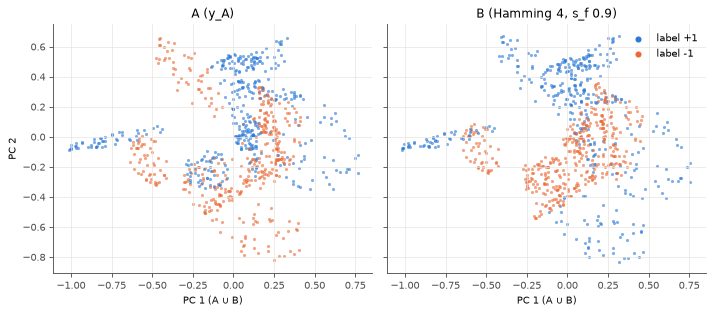

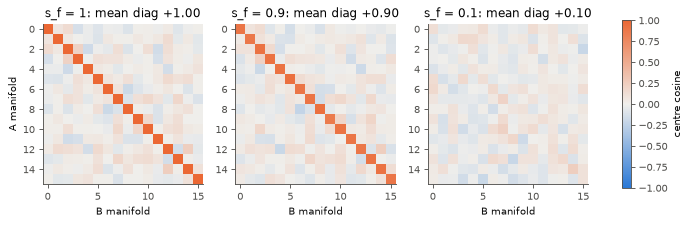

In [3]:
base = L.seed_base(cfg, 0)
H_SHOW, SF_SHOW = 4, 0.9
B_show = L.b_arrangement(cfg, base, SF_SHOW)
pts = np.concatenate([base.A.points.reshape(-1, cfg.d), B_show.points.reshape(-1, cfg.d)])
mu = pts.mean(0); _, _, Vt = np.linalg.svd(pts - mu, full_matrices=False); basis = Vt[:2]

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, arr, y, title in [(axes[0], base.A, base.y_A, "A (y_A)"),
                          (axes[1], B_show, base.y_Bs[H_SHOW], f"B (Hamming {H_SHOW}, s_f {SF_SHOW})")]:
    for m in range(cfg.P):
        Z = (arr.points[m] - mu) @ basis.T
        ax.scatter(Z[:, 0], Z[:, 1], s=8, color=LABEL_COL[int(y[m])], alpha=0.6, linewidths=0)
    ax.set_title(title); ax.set_xlabel("PC 1 (A ∪ B)")
axes[0].set_ylabel("PC 2")
for lab, col in LABEL_COL.items():
    axes[1].scatter([], [], color=col, s=20, label=f"label {lab:+d}")
axes[1].legend(frameon=False, loc="upper right"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(cfg.s_fs), figsize=(11, 3.4))
for ax, sf in zip(axes, cfg.s_fs):
    C = L.centre_cosines(base.A.centers, L.b_arrangement(cfg, base, sf).centers)
    im = ax.imshow(C, cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_title(f"s_f = {sf:g}: mean diag {np.mean(np.diag(C)):+.2f}"); ax.set_xlabel("B manifold"); ax.grid(False)
axes[0].set_ylabel("A manifold"); fig.colorbar(im, ax=axes, shrink=0.8, label="centre cosine"); plt.show()

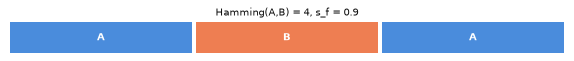

label relations, seed 0 (signed s_r = 1 − 2·Hamming/P):


| Hamming(A,B) | s_r(y_A, y_B) | s_r(y*, y_A) | s_r(y*, y_B) |
|---|---|---|---|
| 0 | +1.000 | +0.500 | +0.500 |
| 4 | +0.500 | +0.500 | +0.000 |
| 8 | +0.000 | +0.500 | +0.250 |

In [4]:
def stream_strip(ax, h, sf, widths=(1, 1, 1)):
    x = 0
    for (lab, col), w in zip([("A", BLUE), ("B", ORANGE), ("A", BLUE)], widths):
        ax.add_patch(plt.Rectangle((x + 0.01, 0), w - 0.02, 1, color=col, alpha=0.85, linewidth=0))
        ax.text(x + w / 2, 0.5, lab, ha="center", va="center", color="white", fontsize=9, weight="bold")
        x += w
    ax.set_xlim(0, x); ax.set_ylim(0, 1); ax.axis("off")
    ax.set_title(f"Hamming(A,B) = {h}, s_f = {sf:g}", fontsize=9, color=INK)

fig, ax = plt.subplots(figsize=(9, 0.5)); stream_strip(ax, H_SHOW, SF_SHOW); plt.show()
print("label relations, seed 0 (signed s_r = 1 − 2·Hamming/P):")
md_table(["Hamming(A,B)", "s_r(y_A, y_B)", "s_r(y*, y_A)", "s_r(y*, y_B)"],
         [[h, f"{L.s_r(base.y_A, yb):+.3f}", f"{L.s_r(base.y_star, base.y_A):+.3f}",
           f"{L.s_r(base.y_star, yb):+.3f}"] for h, yb in base.y_Bs.items()])

## 3. Estimator validation (must pass)

In [5]:
# (a) Vendored GLUE equals src.glue.core on one example, when src imports.
try:
    from src.glue.core import glue_measures as src_glue, Ensemble as SrcEnsemble
except Exception as e:  # noqa: BLE001
    src_glue = None; print("src not importable, comparison skipped:", e)
if src_glue is not None:
    mans = L.as_manifolds(base.A.points)
    y = base.y_A.astype(float)
    a = L.glue_measures(mans, np.random.default_rng(11), n_t=20, ensemble=L.Ensemble("retained", y)).to_dict()
    b = src_glue(mans, np.random.default_rng(11), n_t=20, ensemble=SrcEnsemble("retained", y)).to_dict()
    diff = max(abs(a[k] - b[k]) for k in a if isinstance(a[k], float))
    assert diff == 0.0, f"vendored GLUE differs from src.glue.core by {diff}"
    check("vendored GLUE == src.glue.core (retained y_A, input manifolds)", True, f"max |diff| = {diff:g}")

PASS vendored GLUE == src.glue.core (retained y_A, input manifolds)  (max |diff| = 0)


In [6]:
# (b) Identity residual and (c) capacity falls with R and with D, on input manifolds.
rows, alphas_R, alphas_D, resid = [], [], [], []
for R in (0.5, 1.0, 2.0):
    arr = L.make_arrangement(cfg.P, cfg.d, cfg.D, R, cfg.M, np.random.default_rng([7, 1]), np.random.default_rng([7, 2]))
    g = L.capacity(L.as_manifolds(arr.points), base.y_A, cfg, [L.SALT, 0, 9])
    alphas_R.append(g["alpha"]); resid.append(g["identity_residual"]); rows.append([f"R={R}, D={cfg.D}", f"{g['alpha']:.4f}", f"{g['identity_residual']:.1e}"])
for D in (2, 4, 8):
    arr = L.make_arrangement(cfg.P, cfg.d, D, cfg.R, cfg.M, np.random.default_rng([7, 1]), np.random.default_rng([7, 2]))
    g = L.capacity(L.as_manifolds(arr.points), base.y_A, cfg, [L.SALT, 0, 9])
    alphas_D.append(g["alpha"]); resid.append(g["identity_residual"]); rows.append([f"R={cfg.R}, D={D}", f"{g['alpha']:.4f}", f"{g['identity_residual']:.1e}"])
md_table(["input manifolds", "α (retained y_A)", "identity residual"], rows)
check("identity residual ≈ 0", max(resid) < 1e-10, f"max {max(resid):.1e}")
check("capacity falls as R grows (0.5 → 1 → 2)", bool(np.all(np.diff(alphas_R) < 0)), str([round(a, 4) for a in alphas_R]))
check("capacity falls as D grows (2 → 4 → 8)", bool(np.all(np.diff(alphas_D) < 0)), str([round(a, 4) for a in alphas_D]))

| input manifolds | α (retained y_A) | identity residual |
|---|---|---|
| R=0.5, D=4 | 0.7438 | 0.0e+00 |
| R=1.0, D=4 | 0.4552 | 1.2e-16 |
| R=2.0, D=4 | 0.3129 | 1.8e-16 |
| R=1.0, D=2 | 0.6495 | 1.7e-16 |
| R=1.0, D=4 | 0.4552 | 1.2e-16 |
| R=1.0, D=8 | 0.3402 | 1.6e-16 |

PASS identity residual ≈ 0  (max 1.8e-16)
PASS capacity falls as R grows (0.5 → 1 → 2)  ([0.7438, 0.4552, 0.3129])
PASS capacity falls as D grows (2 → 4 → 8)  ([0.6495, 0.4552, 0.3402])


In [7]:
# (d) Noise floor: SD of log α over K estimator seeds, on the init representation (identical across γ0).
K_FLOOR = 6
net0 = L.OneModuleNet(base.W0, 1.0, cfg)
P_, M_, d_ = base.A.points.shape
Hrep = net0.hidden(base.A.points.reshape(-1, d_)).reshape(P_, M_, -1)
logs = [math.log(L.capacity(L.as_manifolds(Hrep), base.y_A, cfg, [L.SALT, 0, 1000 + k])["alpha"]) for k in range(K_FLOOR)]
FLOOR_INIT = float(np.std(logs, ddof=1))
print(f"INIT floor (reference only; hidden representation at initialisation, identical across γ0): "
      f"SD(log α) over {K_FLOOR} estimator seeds = {FLOOR_INIT:.4f}  (n_t = {cfg.n_t})")
print("Effects are resolved against the per-γ0 floors on the TRAINED representation (section 4).")

INIT floor (reference only; hidden representation at initialisation, identical across γ0): SD(log α) over 6 estimator seeds = 0.0367  (n_t = 50)
Effects are resolved against the per-γ0 floors on the TRAINED representation (section 4).


## 4. Network validation (must pass)

In [8]:
nets = {g: L.OneModuleNet(base.W0, g, cfg) for g in cfg.gammas}
XA, yA = L.flatten(base.A.points, base.y_A)
check("initial loss = 0.5 for every γ0", all(n.loss(XA, yA) == 0.5 for n in nets.values()),
      str({g: n.loss(XA, yA) for g, n in nets.items()}))
check("hidden init identical across γ0 (bitwise)", np.array_equal(nets[cfg.gammas[0]].W, nets[cfg.gammas[1]].W))
probe = np.concatenate([base.A.points[m, base.ntk_idx[m]] for m in range(cfg.P)])
_, KW0 = nets[cfg.gammas[0]].ntk_blocks(probe)
check("K_W(0) = 0 (readout starts at 0)", float(np.abs(KW0).max()) == 0.0)
tmp = L.OneModuleNet(base.W0, 1.0, cfg); tmp.u = np.random.default_rng(3).standard_normal(cfg.N)
fd = L.ntk_fd_check(tmp, probe[:3], np.random.default_rng(4))
check("analytic NTK: J Jᵀ = K_u + K_W and J δ = finite difference",
      fd["K_vs_JJt_rel"] < 1e-12 and fd["Jdelta_vs_fd_rel"] < 1e-5, str({k: f"{v:.1e}" for k, v in fd.items()}))

PASS initial loss = 0.5 for every γ0  ({0.1: 0.5, 10.0: 0.5})
PASS hidden init identical across γ0 (bitwise)
PASS K_W(0) = 0 (readout starts at 0)
PASS analytic NTK: J Jᵀ = K_u + K_W and J δ = finite difference  ({'K_vs_JJt_rel': '3.4e-16', 'Jdelta_vs_fd_rel': '5.9e-08'})


In [9]:
# Lazy/rich separation after A, and reaching the target within budget, for every seed and γ0.
sep_rows, sep, budget_ok = [], {}, []
for seed in range(cfg.n_seeds):
    b = L.seed_base(cfg, seed)
    X, y = L.flatten(b.A.points, b.y_A)
    pr = np.concatenate([b.A.points[m, b.ntk_idx[m]] for m in range(cfg.P)])
    yp = np.repeat(b.y_A.astype(float), b.ntk_idx.shape[1])
    for g in cfg.gammas:
        n = L.OneModuleNet(b.W0, g, cfg); Ku0, KW0 = n.ntk_blocks(pr)
        t = L.train_to_criterion(n, X, y, cfg)
        budget_ok.append((seed, g, t["status"], t["steps"]))
        sep[(seed, g)] = L.richness_snapshot(n, Ku0 + KW0, Ku0, pr, yp, pr, yp)[0]
display(Markdown("**NTK change after training on A: absolute values, not ratios.** All three are "
                  "‖·‖_F / ‖K(0)‖_F on A's fixed probe set; K(0) = K_u(0) because K_W(0) = 0. "
                  "ΔK_W is the hidden-weight block grown from zero; ΔK full = ‖ΔK_u + K_W‖."))
NTK_KEYS = [("dK_full", "ΔK full"), ("dK_u", "ΔK_u"), ("dK_W", "ΔK_W"), ("weight_change", "weight change")]
rows = []
for g in cfg.gammas:
    for seed in range(cfg.n_seeds):
        rows.append([f"{g:g}", seed] + [f"{sep[(seed, g)][k]:.4g}" for k, _ in NTK_KEYS])
    rows.append([f"**{g:g}**", "**mean**"] + [f"**{np.mean([sep[(s, g)][k] for s in range(cfg.n_seeds)]):.4g}**" for k, _ in NTK_KEYS])
md_table(["γ0", "seed"] + [lab for _, lab in NTK_KEYS], rows)
for k in ("weight_change", "dK_u", "dK_full"):
    check(f"rich > lazy after A in {k}, every seed",
          all(sep[(s, cfg.gammas[1])][k] > sep[(s, cfg.gammas[0])][k] for s in range(cfg.n_seeds)),
          "direction only; any ratio threshold is Kati's")
md_table(["seed", "γ0", "status", "steps on A"], [[s, f"{g:g}", st, n] for s, g, st, n in budget_ok])
check(f"every γ0 reaches loss {cfg.target_loss} within {cfg.max_steps} steps at lr0 = {cfg.lr0}",
      all(st == "converged" for _, _, st, _ in budget_ok), "a failure is reported, never re-pinned")

**NTK change after training on A: absolute values, not ratios.** All three are ‖·‖_F / ‖K(0)‖_F on A's fixed probe set; K(0) = K_u(0) because K_W(0) = 0. ΔK_W is the hidden-weight block grown from zero; ΔK full = ‖ΔK_u + K_W‖.

| γ0 | seed | ΔK full | ΔK_u | ΔK_W | weight change |
|---|---|---|---|---|---|
| 0.1 | 0 | 0.1824 | 0.04491 | 0.1589 | 0.0186 |
| 0.1 | 1 | 0.1842 | 0.04813 | 0.1592 | 0.01945 |
| 0.1 | 2 | 0.2037 | 0.04291 | 0.1832 | 0.02183 |
| **0.1** | **mean** | **0.1901** | **0.04532** | **0.1671** | **0.01996** |
| 10 | 0 | 33.44 | 8.055 | 29.42 | 0.598 |
| 10 | 1 | 32.19 | 8.277 | 27.98 | 0.6013 |
| 10 | 2 | 34.98 | 7.099 | 31.74 | 0.6447 |
| **10** | **mean** | **33.53** | **7.811** | **29.71** | **0.6146** |

PASS rich > lazy after A in weight_change, every seed  (direction only; any ratio threshold is Kati's)
PASS rich > lazy after A in dK_u, every seed  (direction only; any ratio threshold is Kati's)
PASS rich > lazy after A in dK_full, every seed  (direction only; any ratio threshold is Kati's)


| seed | γ0 | status | steps on A |
|---|---|---|---|
| 0 | 0.1 | converged | 1610 |
| 0 | 10 | converged | 45 |
| 1 | 0.1 | converged | 1660 |
| 1 | 10 | converged | 45 |
| 2 | 0.1 | converged | 1935 |
| 2 | 10 | converged | 52 |

PASS every γ0 reaches loss 0.05 within 20000 steps at lr0 = 5.0  (a failure is reported, never re-pinned)


In [10]:
# Noise floor per γ0 on the hidden representation AFTER training on A (seed 0, K estimator seeds).
FLOORS = {g: L.trained_floor(cfg, g, seed=0, K=K_FLOOR) for g in cfg.gammas}
md_table(["γ0", "floor SD(log α_A), trained", "K", "n_t", "mean log α_A after A"],
         [[f"{g:g}", f"{f['floor']:.4f}", f["K"], f["n_t"], f"{f['mean_log_alpha']:+.3f}"] for g, f in FLOORS.items()]
         + [["init (reference)", f"{FLOOR_INIT:.4f}", K_FLOOR, cfg.n_t, ""]])
T975 = {2: 4.303, 3: 3.182, 4: 2.776, 5: 2.571, 6: 2.447, 7: 2.365, 8: 2.306}   # t quantiles, df = n − 1 ≥ 2

def resolve(values, floor):
    # docs/26 A4: resolved iff the 95% t-interval over unique draws excludes 0 AND |mean| ≥ 2 floors.
    v = np.asarray(values, float); n = v.size; m = float(v.mean())
    if n < 2: return {"mean": m, "lo": float("nan"), "hi": float("nan"), "n": n, "resolved": False, "sign": 0}
    h = T975.get(n - 1, 1.96) * float(v.std(ddof=1)) / math.sqrt(n)
    res = (m - h > 0 or m + h < 0) and abs(m) >= 2 * floor
    return {"mean": m, "lo": m - h, "hi": m + h, "n": n, "resolved": bool(res), "sign": int(np.sign(m)) if res else 0}

| γ0 | floor SD(log α_A), trained | K | n_t | mean log α_A after A |
|---|---|---|---|---|
| 0.1 | 0.0448 | 6 | 50 | -0.804 |
| 10 | 0.0829 | 6 | 50 | +1.103 |
| init (reference) | 0.0367 | 6 | 50 |  |

## Expectations (written before the grid)

These are directions from earlier signal, not thresholds. They were written on
2026-11-08 before any grid arm ran. After the run, each reading quotes them verbatim
and marks it **held**, **not held**, or **unresolved at floor**.

1. forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1;
2. at γ0 = 10, the utility channel carries most of Δlog α_A;
3. Hamming 0 under drift (s_f 0.9) gives Δlog α_A > 0 (gain);
4. Hamming 4 and 8 are similar (cliff, not dose);
5. K_u change separates γ0 more cleanly than the full NTK change.

**How each is read.** This is fixed before the run.

**Measure.** Δlog α_A means A's retained capacity from the end of A to the end
of B (`backward.A1_to_B`).

**Resolution rule.** "Resolved" means the 95% t-interval over the n unique draws
excludes 0 **and** |mean| ≥ 2 floors. The floor is the per-γ0 trained-representation
floor. For contrasts across γ0, the floor is the larger of the two.

**Rules per expectation:**

| # | statistic | held | not held | unresolved |
|---|---|---|---|---|
| 1 | per s_f, paired per seed: d = Δlog α_A(γ0=10) − Δlog α_A(γ0=0.1) at Hamming 8 | d resolved < 0 | d resolved > 0 | otherwise |
| 2 | at γ0 = 10, per cell with Hamming ∈ {4, 8} and per (Hamming 0, s_f ∈ {0.9, 0.1}): utility fraction = mean utility / mean total | total resolved and fraction > 0.5 | total resolved and fraction ≤ 0.5 | total unresolved |
| 3 | per γ0: Δlog α_A at Hamming 0, s_f 0.9 | resolved > 0 | resolved < 0 | otherwise |
| 4 | per (γ0, s_f), paired per seed: d = Δlog α_A(Hamming 8) − Δlog α_A(Hamming 4) | 95% interval of d inside ±2 floors (equivalence) | d resolved (differs) | otherwise |
| 5 | after A, over unique (seed, γ0): separation d′ = (mean log x at γ0=10 − mean log x at γ0=0.1) / pooled SD of log x, for x = ΔK_u and x = ΔK full | d′(ΔK_u) > d′(ΔK full) | d′(ΔK_u) ≤ d′(ΔK full) | not used (no capacity floor applies) |

Expectation 5 also reports the absolute lazy values, which are expected to be ≪ 1.

Stratified readings are not pooled. An expectation that holds in some strata and not
others is reported stratum by stratum.

## 5. Runs

**Timing first.** One QUICK arm runs in a spawned worker before anything else. The arm
is γ₀ = 0.1, Hamming 8, s_f = 0.1: lazy training takes the most steps, so this is
expected to be the slowest cell. The full grid runs only when `RUN_GRID = True`. It
includes the identity control (Hamming 0, s_f 1.0) and a **fresh-noise identity
arm**: same manifolds, ε noise redrawn, seed 0, both γ₀. That arm checks the
"frozen = exact copy" choice. Every arm is checkpointed to `results/aba/`, keyed by
the `aba_lib` hash and the config.

In [11]:
TIMING_SPEC = L.ArmSpec(0, cfg.gammas[0], max(cfg.hammings), min(cfg.s_fs))
t0 = time.perf_counter()
timing_arm = L.run_grid(cfg, [TIMING_SPEC], workers=1)[0]
tm = timing_arm["timing"]
print(f"timing arm {TIMING_SPEC.key}: wall {tm['wall_s']:.1f}s in worker "
      f"(train {tm['train_s']:.1f}s, GLUE {tm['glue_s']:.1f}s, NTK {tm['ntk_s']:.1f}s); "
      f"cell {time.perf_counter() - t0:.1f}s incl. spawn or cache load")
print("steps:", timing_arm["behaviour"]["steps"], " usable:", timing_arm["usable"])

timing arm seed=0,gamma=0.1,H=8,s_f=0.1: wall 121.5s in worker (train 99.4s, GLUE 19.3s, NTK 0.2s); cell 0.3s incl. spawn or cache load
steps: {'A1': 1610, 'B': 1430, 'A2': 369, 'freshB': 1732}  usable: True


In [12]:
if RUN_GRID:
    t0 = time.perf_counter()
    L.run_grid(cfg, L.all_specs(cfg), workers=WORKERS)
    GRID_WALL = time.perf_counter() - t0
    print(f"grid: {len(L.all_specs(cfg))} arms requested, wall {GRID_WALL:.0f}s on {WORKERS} workers")
loaded = L.load_results(cfg)
FRESH = [r for r in loaded if r["spec"].get("noise", "copy") == "fresh"]
arms = [r for r in loaded if r["usable"] and r["spec"].get("noise", "copy") == "copy"]
unusable = [r["key"] for r in loaded if not r["usable"]]
print(f"{len(arms)} usable design arms + {len(FRESH)} fresh-noise arms loaded; unusable: {unusable or 'none'}")
stamps = {(r["stamp"]["commit"], r["stamp"]["dirty"], r["lib_hash"]) for r in loaded}
print("provenance (commit, dirty, lib hash):", stamps)
check("every arm stamped with a clean tree", all(r["stamp"]["dirty"] is False for r in loaded),
      str(sorted({str(s[1]) for s in stamps})))

grid: 56 arms requested, wall 0s on 6 workers
54 usable design arms + 2 fresh-noise arms loaded; unusable: none
provenance (commit, dirty, lib hash): {('ee2c1b63b79b', False, '9cc174b574654db2')}
PASS every arm stamped with a clean tree  (['False'])


In [13]:
# Identity control (exact copy) and the fresh-noise identity arm, both read from the grid.
for r in [x for x in arms if x["spec"]["hamming"] == 0 and x["spec"]["s_f"] == 1.0 and x["spec"]["seed"] == 0]:
    st, bw = r["behaviour"]["steps"], r["backward"]
    ok = (st["B"] == 0 and st["A2"] == 0 and r["behaviour"]["forget_B_loss"]["forgetting"] == 0.0
          and all(v == 0.0 for v in bw["A1_to_B"].values()) and all(v == 0.0 for v in bw["A1_to_A2"].values()))
    check(f"identity control (Hamming 0, s_f 1.0, copy), γ0={r['spec']['gamma']:g}: 0 steps on B and A2, zero forgetting, Δlog α_A = 0",
          ok, f"steps {st}")
rows = []
for r in sorted(FRESH, key=lambda x: x["spec"]["gamma"]):
    g = r["spec"]["gamma"]; st = r["behaviour"]["steps"]; d = r["backward"]["A1_to_B"]["total"]
    fl = r["behaviour"]["forget_B_loss"]["forgetting"]
    rows.append([f"{g:g}", st["A1"], st["B"], st["A2"], f"{d:+.5f}", f"{d / FLOORS[g]['floor']:+.3f}",
                 f"{fl:+.2e}", f"{r['behaviour']['first_loss']['B']:.5f}"])
    check(f"fresh-noise identity, γ0={g:g}: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target",
          abs(d) < FLOORS[g]["floor"] and r["behaviour"]["first_loss"]["B"] < 2 * cfg.target_loss,
          f"Δlog α_A = {d:+.5f} ({d / FLOORS[g]['floor']:+.2f} floors), steps on B = {st['B']}")
md_table(["γ0", "steps A1", "steps B", "steps A2", "Δlog α_A (A1→B)", "in floors", "forgetting (test loss)", "zero-shot loss on B"], rows)

PASS identity control (Hamming 0, s_f 1.0, copy), γ0=0.1: 0 steps on B and A2, zero forgetting, Δlog α_A = 0  (steps {'A1': 1610, 'B': 0, 'A2': 0, 'freshB': 1610})
PASS identity control (Hamming 0, s_f 1.0, copy), γ0=10: 0 steps on B and A2, zero forgetting, Δlog α_A = 0  (steps {'A1': 45, 'B': 0, 'A2': 0, 'freshB': 45})
PASS fresh-noise identity, γ0=0.1: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target  (Δlog α_A = +0.00010 (+0.00 floors), steps on B = 1)
PASS fresh-noise identity, γ0=10: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target  (Δlog α_A = +0.00000 (+0.00 floors), steps on B = 0)


| γ0 | steps A1 | steps B | steps A2 | Δlog α_A (A1→B) | in floors | forgetting (test loss) | zero-shot loss on B |
|---|---|---|---|---|---|---|---|
| 0.1 | 1610 | 1 | 0 | +0.00010 | +0.002 | -5.90e-05 | 0.05006 |
| 10 | 45 | 0 | 0 | +0.00000 | +0.000 | +0.00e+00 | 0.04693 |

### Per-arm output schema

Every arm must carry each field below, finite. Groups:
- **backward:** Δlog α_A in three channels plus total and residual, at each phase
  (init→A, A→B, B→A, A→ABA).
- **forgetting:** against the running max (accuracy) or running min (loss).
- **forward:** FT_geo with the neutral probes y\*_k (s_r = 0 to y_A; specific = Δlog α_{y_B}
  − mean_k Δlog α_{y*_k}), the anchored y\* kept for comparison, and the signed s_r relations.
- **refit:** a fresh readout fitted on frozen features at init, after A, after B and after A
  again (fixed budget `cfg.refit_steps`), scored on A's test points.
- **behaviour:** FT_beh against a fresh learner, savings, raw steps, and zero-shot
  losses.
- **richness:** weight change, r_t, ΔK full, ΔK_u and ΔK_W from init and from the previous
  boundary (`*_step`, plus kernel alignment `align_step`), NTK–label alignment.
- **geometry:** ρ_c signed and `glue`.

In [14]:
md_table(["field", "meaning"], [[f"`{k}`", v] for k, v in L.SCHEMA.items()])
bad = {r["key"]: L.check_schema(r) for r in loaded}
bad = {k: v for k, v in bad.items() if v}
assert not bad, f"schema violations: {bad}"
check(f"schema: all {len(L.SCHEMA)} fields present and finite in all {len(loaded)} arms", True)

| field | meaning |
|---|---|
| `backward.init_to_A1.total` | Δlog α_A init_to_A1, channel total |
| `backward.init_to_A1.utility` | Δlog α_A init_to_A1, channel utility |
| `backward.init_to_A1.radius` | Δlog α_A init_to_A1, channel radius |
| `backward.init_to_A1.dimension` | Δlog α_A init_to_A1, channel dimension |
| `backward.init_to_A1.residual` | Δlog α_A init_to_A1, channel residual |
| `backward.A1_to_B.total` | Δlog α_A A1_to_B, channel total |
| `backward.A1_to_B.utility` | Δlog α_A A1_to_B, channel utility |
| `backward.A1_to_B.radius` | Δlog α_A A1_to_B, channel radius |
| `backward.A1_to_B.dimension` | Δlog α_A A1_to_B, channel dimension |
| `backward.A1_to_B.residual` | Δlog α_A A1_to_B, channel residual |
| `backward.B_to_A2.total` | Δlog α_A B_to_A2, channel total |
| `backward.B_to_A2.utility` | Δlog α_A B_to_A2, channel utility |
| `backward.B_to_A2.radius` | Δlog α_A B_to_A2, channel radius |
| `backward.B_to_A2.dimension` | Δlog α_A B_to_A2, channel dimension |
| `backward.B_to_A2.residual` | Δlog α_A B_to_A2, channel residual |
| `backward.A1_to_A2.total` | Δlog α_A A1_to_A2, channel total |
| `backward.A1_to_A2.utility` | Δlog α_A A1_to_A2, channel utility |
| `backward.A1_to_A2.radius` | Δlog α_A A1_to_A2, channel radius |
| `backward.A1_to_A2.dimension` | Δlog α_A A1_to_A2, channel dimension |
| `backward.A1_to_A2.residual` | Δlog α_A A1_to_A2, channel residual |
| `behaviour.forget_B_acc.peak` | forgetting on A during B vs running max (peak) |
| `behaviour.forget_B_acc.final` | forgetting on A during B vs running max (final) |
| `behaviour.forget_B_acc.forgetting` | forgetting on A during B vs running max (forgetting) |
| `behaviour.forget_B_loss.peak` | forgetting on A during B vs running min (peak) |
| `behaviour.forget_B_loss.final` | forgetting on A during B vs running min (final) |
| `behaviour.forget_B_loss.forgetting` | forgetting on A during B vs running min (forgetting) |
| `forward.total.total` | Δlog α_{y_B} on B's manifolds, init → after A, total |
| `forward.total.utility` | Δlog α_{y_B} on B's manifolds, init → after A, utility |
| `forward.total.radius` | Δlog α_{y_B} on B's manifolds, init → after A, radius |
| `forward.total.dimension` | Δlog α_{y_B} on B's manifolds, init → after A, dimension |
| `forward.total.residual` | Δlog α_{y_B} on B's manifolds, init → after A, residual |
| `forward.ystar_neutral.0` | Δlog α_{y*_0} (neutral, s_r = 0 to y_A) on B's manifolds, init → after A |
| `forward.ystar_neutral.1` | Δlog α_{y*_1} (neutral, s_r = 0 to y_A) on B's manifolds, init → after A |
| `forward.ystar_neutral.2` | Δlog α_{y*_2} (neutral, s_r = 0 to y_A) on B's manifolds, init → after A |
| `forward.ystar_neutral.3` | Δlog α_{y*_3} (neutral, s_r = 0 to y_A) on B's manifolds, init → after A |
| `forward.ystar_neutral.mean` | Δlog α_{y*_mean} (neutral, s_r = 0 to y_A) on B's manifolds, init → after A |
| `forward.specific` | FT_geo specific = Δlog α_{y_B} − mean_k Δlog α_{y*_k} (neutral baseline) |
| `forward.ystar_anchored` | Δlog α_{y*} for the anchored probe (s_r = +0.5 to y_A); comparison only |
| `forward.specific_anchored` | Δlog α_{y_B} − Δlog α_{y* anchored}; comparison only |
| `relations.s_r_AB` | s_r(y_A, y_B), signed |
| `relations.s_r_ystar_A` | s_r(y* anchored, y_A), signed |
| `relations.s_r_ystar_B` | s_r(y* anchored, y_B), signed |
| `relations.s_r_ystar_neutral_A.0` | s_r(y*_0 neutral, y_A) |
| `relations.s_r_ystar_neutral_A.1` | s_r(y*_1 neutral, y_A) |
| `relations.s_r_ystar_neutral_A.2` | s_r(y*_2 neutral, y_A) |
| `relations.s_r_ystar_neutral_A.3` | s_r(y*_3 neutral, y_A) |
| `relations.s_r_ystar_neutral_B.0` | s_r(y*_0 neutral, y_B) |
| `relations.s_r_ystar_neutral_B.1` | s_r(y*_1 neutral, y_B) |
| `relations.s_r_ystar_neutral_B.2` | s_r(y*_2 neutral, y_B) |
| `relations.s_r_ystar_neutral_B.3` | s_r(y*_3 neutral, y_B) |
| `refit.init.loss` | fresh readout on frozen features after init, loss |
| `refit.init.acc` | fresh readout on frozen features after init, acc |
| `refit.init.train_loss` | fresh readout on frozen features after init, train_loss |
| `refit.init.loss@100` | fresh readout on frozen features after init, loss@100 |
| `refit.init.acc@100` | fresh readout on frozen features after init, acc@100 |
| `refit.init.loss@500` | fresh readout on frozen features after init, loss@500 |
| `refit.init.acc@500` | fresh readout on frozen features after init, acc@500 |
| `refit.A1.loss` | fresh readout on frozen features after A1, loss |
| `refit.A1.acc` | fresh readout on frozen features after A1, acc |
| `refit.A1.train_loss` | fresh readout on frozen features after A1, train_loss |
| `refit.A1.loss@100` | fresh readout on frozen features after A1, loss@100 |
| `refit.A1.acc@100` | fresh readout on frozen features after A1, acc@100 |
| `refit.A1.loss@500` | fresh readout on frozen features after A1, loss@500 |
| `refit.A1.acc@500` | fresh readout on frozen features after A1, acc@500 |
| `refit.B.loss` | fresh readout on frozen features after B, loss |
| `refit.B.acc` | fresh readout on frozen features after B, acc |
| `refit.B.train_loss` | fresh readout on frozen features after B, train_loss |
| `refit.B.loss@100` | fresh readout on frozen features after B, loss@100 |
| `refit.B.acc@100` | fresh readout on frozen features after B, acc@100 |
| `refit.B.loss@500` | fresh readout on frozen features after B, loss@500 |
| `refit.B.acc@500` | fresh readout on frozen features after B, acc@500 |
| `refit.A2.loss` | fresh readout on frozen features after A2, loss |
| `refit.A2.acc` | fresh readout on frozen features after A2, acc |
| `refit.A2.train_loss` | fresh readout on frozen features after A2, train_loss |
| `refit.A2.loss@100` | fresh readout on frozen features after A2, loss@100 |
| `refit.A2.acc@100` | fresh readout on frozen features after A2, acc@100 |
| `refit.A2.loss@500` | fresh readout on frozen features after A2, loss@500 |
| `refit.A2.acc@500` | fresh readout on frozen features after A2, acc@500 |
| `richness.A1.dK_full_step` | dK_full_step: kernel change from previous boundary to A1 |
| `richness.A1.dK_u_step` | dK_u_step: kernel change from previous boundary to A1 |
| `richness.A1.dK_W_step` | dK_W_step: kernel change from previous boundary to A1 |
| `richness.A1.align_step` | align_step: kernel change from previous boundary to A1 |
| `richness.B.dK_full_step` | dK_full_step: kernel change from previous boundary to B |
| `richness.B.dK_u_step` | dK_u_step: kernel change from previous boundary to B |
| `richness.B.dK_W_step` | dK_W_step: kernel change from previous boundary to B |
| `richness.B.align_step` | align_step: kernel change from previous boundary to B |
| `richness.A2.dK_full_step` | dK_full_step: kernel change from previous boundary to A2 |
| `richness.A2.dK_u_step` | dK_u_step: kernel change from previous boundary to A2 |
| `richness.A2.dK_W_step` | dK_W_step: kernel change from previous boundary to A2 |
| `richness.A2.align_step` | align_step: kernel change from previous boundary to A2 |
| `relations.rho_in_AB` | mean centre cosine A ↔ B (input relation) |
| `behaviour.FT_beh` | log((1+steps fresh B)/(1+steps B)) |
| `behaviour.savings` | log((1+steps A1)/(1+steps A2)) |
| `behaviour.steps.A1` | raw steps, A1 |
| `behaviour.steps.B` | raw steps, B |
| `behaviour.steps.A2` | raw steps, A2 |
| `behaviour.steps.freshB` | raw steps, freshB |
| `behaviour.first_loss.A1` | zero-shot loss, A1 |
| `behaviour.first_loss.B` | zero-shot loss, B |
| `behaviour.first_loss.A2` | zero-shot loss, A2 |
| `behaviour.first_loss.freshB` | zero-shot loss, freshB |
| `richness.init.weight_change` | weight_change after init |
| `richness.init.dK_full` | dK_full after init |
| `richness.init.dK_u` | dK_u after init |
| `richness.init.dK_W` | dK_W after init |
| `richness.init.KW_share` | KW_share after init |
| `richness.init.cka_K_yA` | cka_K_yA after init |
| `richness.init.cka_K_yB` | cka_K_yB after init |
| `richness.A1.weight_change` | weight_change after A1 |
| `richness.A1.dK_full` | dK_full after A1 |
| `richness.A1.dK_u` | dK_u after A1 |
| `richness.A1.dK_W` | dK_W after A1 |
| `richness.A1.KW_share` | KW_share after A1 |
| `richness.A1.cka_K_yA` | cka_K_yA after A1 |
| `richness.A1.cka_K_yB` | cka_K_yB after A1 |
| `richness.B.weight_change` | weight_change after B |
| `richness.B.dK_full` | dK_full after B |
| `richness.B.dK_u` | dK_u after B |
| `richness.B.dK_W` | dK_W after B |
| `richness.B.KW_share` | KW_share after B |
| `richness.B.cka_K_yA` | cka_K_yA after B |
| `richness.B.cka_K_yB` | cka_K_yB after B |
| `richness.A2.weight_change` | weight_change after A2 |
| `richness.A2.dK_full` | dK_full after A2 |
| `richness.A2.dK_u` | dK_u after A2 |
| `richness.A2.dK_W` | dK_W after A2 |
| `richness.A2.KW_share` | KW_share after A2 |
| `richness.A2.cka_K_yA` | cka_K_yA after A2 |
| `richness.A2.cka_K_yB` | cka_K_yB after A2 |
| `richness.r_t.A1` | r_t within A1 |
| `richness.r_t.B` | r_t within B |
| `richness.r_t.A2` | r_t within A2 |
| `geometry.A@init.rho_c_signed` | rho_c_signed at A@init |
| `geometry.A@init.rho_c_glue` | rho_c_glue at A@init |
| `geometry.A@init.alpha` | alpha at A@init |
| `geometry.A@init.identity_residual` | identity_residual at A@init |
| `geometry.A@A1.rho_c_signed` | rho_c_signed at A@A1 |
| `geometry.A@A1.rho_c_glue` | rho_c_glue at A@A1 |
| `geometry.A@A1.alpha` | alpha at A@A1 |
| `geometry.A@A1.identity_residual` | identity_residual at A@A1 |
| `geometry.A@B.rho_c_signed` | rho_c_signed at A@B |
| `geometry.A@B.rho_c_glue` | rho_c_glue at A@B |
| `geometry.A@B.alpha` | alpha at A@B |
| `geometry.A@B.identity_residual` | identity_residual at A@B |
| `geometry.A@A2.rho_c_signed` | rho_c_signed at A@A2 |
| `geometry.A@A2.rho_c_glue` | rho_c_glue at A@A2 |
| `geometry.A@A2.alpha` | alpha at A@A2 |
| `geometry.A@A2.identity_residual` | identity_residual at A@A2 |

PASS schema: all 148 fields present and finite in all 56 arms


### Validation checks (must pass)

In [15]:
md_table(["check", "result", "detail"], CHECKS)
n_fail = sum(c[1] != "PASS" for c in CHECKS)
print("ALL VALIDATION CHECKS PASS" if n_fail == 0 else f"{n_fail} VALIDATION CHECK(S) FAILED. Do not read section 6.")

| check | result | detail |
|---|---|---|
| vendored GLUE == src.glue.core (retained y_A, input manifolds) | PASS | max |diff| = 0 |
| identity residual ≈ 0 | PASS | max 1.8e-16 |
| capacity falls as R grows (0.5 → 1 → 2) | PASS | [0.7438, 0.4552, 0.3129] |
| capacity falls as D grows (2 → 4 → 8) | PASS | [0.6495, 0.4552, 0.3402] |
| initial loss = 0.5 for every γ0 | PASS | {0.1: 0.5, 10.0: 0.5} |
| hidden init identical across γ0 (bitwise) | PASS |  |
| K_W(0) = 0 (readout starts at 0) | PASS |  |
| analytic NTK: J Jᵀ = K_u + K_W and J δ = finite difference | PASS | {'K_vs_JJt_rel': '3.4e-16', 'Jdelta_vs_fd_rel': '5.9e-08'} |
| rich > lazy after A in weight_change, every seed | PASS | direction only; any ratio threshold is Kati's |
| rich > lazy after A in dK_u, every seed | PASS | direction only; any ratio threshold is Kati's |
| rich > lazy after A in dK_full, every seed | PASS | direction only; any ratio threshold is Kati's |
| every γ0 reaches loss 0.05 within 20000 steps at lr0 = 5.0 | PASS | a failure is reported, never re-pinned |
| every arm stamped with a clean tree | PASS | ['False'] |
| identity control (Hamming 0, s_f 1.0, copy), γ0=0.1: 0 steps on B and A2, zero forgetting, Δlog α_A = 0 | PASS | steps {'A1': 1610, 'B': 0, 'A2': 0, 'freshB': 1610} |
| identity control (Hamming 0, s_f 1.0, copy), γ0=10: 0 steps on B and A2, zero forgetting, Δlog α_A = 0 | PASS | steps {'A1': 45, 'B': 0, 'A2': 0, 'freshB': 45} |
| fresh-noise identity, γ0=0.1: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target | PASS | Δlog α_A = +0.00010 (+0.00 floors), steps on B = 1 |
| fresh-noise identity, γ0=10: |Δlog α_A| < 1 floor and zero-shot loss on B < 2× target | PASS | Δlog α_A = +0.00000 (+0.00 floors), steps on B = 0 |
| schema: all 148 fields present and finite in all 56 arms | PASS |  |

ALL VALIDATION CHECKS PASS


## 6. Results: one figure or table per question

Signed values only. Positive Δlog α means A's capacity grew; negative means forgetting.
Each cell has n = 3 at QUICK, so these are **observations, not claims**.

In [16]:
def sel(g=None, h=None, sf=None, rows=None):
    rows = arms if rows is None else rows
    return [r for r in rows if (g is None or r["spec"]["gamma"] == g) and (h is None or r["spec"]["hamming"] == h)
            and (sf is None or r["spec"]["s_f"] == sf)]
HAVE = len(arms) >= 10
if not HAVE:
    print("Grid not run yet (RUN_GRID = False). Figures below need the grid.")
FL = {g: FLOORS[g]["floor"] for g in cfg.gammas}
def mci(values, prec=3):
    v = np.asarray(values, float); m = v.mean()
    if v.size < 2: return f"{m:+.{prec}f}"
    h = T975.get(v.size - 1, 1.96) * v.std(ddof=1) / math.sqrt(v.size)
    return f"{m:+.{prec}f} [{m - h:+.{prec}f}, {m + h:+.{prec}f}]"
CELLS = [(g, sf, h) for g in cfg.gammas for sf in cfg.s_fs for h in cfg.hammings]
IDENTITY = lambda h, sf: h == 0 and sf == 1.0

**Q0. Levels.** log α_A at init, after A, after B and after A again, mean [95% t-CI] over
seeds. The init level is the same for both γ₀ (same W(0); the readout is not involved).

The second table expresses the A1→B change against what A built:
- **fraction removed** = (log α_A1 − log α_B) / (log α_A1 − log α_init), per seed;
- the **channel split** of the A1→B change, each channel divided by the init→A1 total gain.

The fraction is shown in parentheses and not read where the init→A1 gain is unresolved
(CI includes 0 or |mean| < 2 floors).

In [17]:
LV = ("A@init", "A@A1", "A@B", "A@A2")
la = lambda r, b: math.log(r["geometry"][b]["alpha"])
if HAVE:
    rows = []
    for g, sf, h in CELLS:
        rs = sel(g, h, sf)
        if rs: rows.append([f"{g:g}", f"{sf:g}", h, len(rs)] + [mci([la(r, b) for r in rs]) for b in LV])
    md_table(["γ0", "s_f", "H", "n", "log α_A init", "after A", "after B", "after A again"], rows)
    rows = []
    for g, sf, h in CELLS:
        rs = sel(g, h, sf)
        if not rs: continue
        gain = [r["backward"]["init_to_A1"]["total"] for r in rs]
        gres = resolve(gain, FL[g])["resolved"]
        frac = [(la(r, "A@A1") - la(r, "A@B")) / (la(r, "A@A1") - la(r, "A@init")) for r in rs]
        split = lambda ch: mci([r["backward"]["A1_to_B"][ch] / r["backward"]["init_to_A1"]["total"] for r in rs])
        rows.append([f"{g:g}", f"{sf:g}", h, mci(gain), "yes" if gres else "**no**",
                     mci(frac) if gres else f"({mci(frac)})", split("utility"), split("radius"), split("dimension")])
    md_table(["γ0", "s_f", "H", "gain init→A1 (Δlog α_A)", "gain resolved", "fraction of learned capacity removed by B",
              "utility / gain", "radius / gain", "dimension / gain"], rows)

| γ0 | s_f | H | n | log α_A init | after A | after B | after A again |
|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | 3 | -1.023 [-1.233, -0.812] | -0.803 [-0.982, -0.625] | -0.803 [-0.982, -0.625] | -0.803 [-0.982, -0.625] |
| 0.1 | 1 | 4 | 3 | -1.023 [-1.233, -0.812] | -0.803 [-0.982, -0.625] | -0.889 [-1.086, -0.692] | -0.759 [-0.923, -0.596] |
| 0.1 | 1 | 8 | 3 | -1.023 [-1.233, -0.812] | -0.803 [-0.982, -0.625] | -0.977 [-1.158, -0.796] | -0.777 [-0.967, -0.587] |
| 0.1 | 0.9 | 0 | 3 | -1.023 [-1.233, -0.812] | -0.803 [-0.982, -0.625] | -0.782 [-0.947, -0.617] | -0.782 [-0.947, -0.617] |
| 0.1 | 0.9 | 4 | 3 | -1.023 [-1.233, -0.812] | -0.803 [-0.982, -0.625] | -0.872 [-1.069, -0.674] | -0.760 [-0.941, -0.579] |
| 0.1 | 0.9 | 8 | 3 | -1.023 [-1.233, -0.812] | -0.803 [-0.982, -0.625] | -0.959 [-1.127, -0.791] | -0.784 [-0.966, -0.601] |
| 0.1 | 0.1 | 0 | 3 | -1.023 [-1.233, -0.812] | -0.803 [-0.982, -0.625] | -0.786 [-0.973, -0.600] | -0.774 [-0.960, -0.588] |
| 0.1 | 0.1 | 4 | 3 | -1.023 [-1.233, -0.812] | -0.803 [-0.982, -0.625] | -0.823 [-1.059, -0.588] | -0.787 [-0.998, -0.575] |
| 0.1 | 0.1 | 8 | 3 | -1.023 [-1.233, -0.812] | -0.803 [-0.982, -0.625] | -0.834 [-1.004, -0.663] | -0.799 [-0.975, -0.623] |
| 10 | 1 | 0 | 3 | -1.023 [-1.233, -0.812] | +0.998 [+0.598, +1.397] | +0.998 [+0.598, +1.397] | +0.998 [+0.598, +1.397] |
| 10 | 1 | 4 | 3 | -1.023 [-1.233, -0.812] | +0.998 [+0.598, +1.397] | -0.534 [-0.884, -0.185] | +0.914 [+0.699, +1.129] |
| 10 | 1 | 8 | 3 | -1.023 [-1.233, -0.812] | +0.998 [+0.598, +1.397] | -0.808 [-0.939, -0.677] | +0.905 [+0.650, +1.160] |
| 10 | 0.9 | 0 | 3 | -1.023 [-1.233, -0.812] | +0.998 [+0.598, +1.397] | +1.042 [+0.687, +1.398] | +1.042 [+0.687, +1.398] |
| 10 | 0.9 | 4 | 3 | -1.023 [-1.233, -0.812] | +0.998 [+0.598, +1.397] | -0.305 [-0.622, +0.012] | +0.914 [+0.731, +1.097] |
| 10 | 0.9 | 8 | 3 | -1.023 [-1.233, -0.812] | +0.998 [+0.598, +1.397] | -0.734 [-0.853, -0.615] | +0.937 [+0.626, +1.248] |
| 10 | 0.1 | 0 | 3 | -1.023 [-1.233, -0.812] | +0.998 [+0.598, +1.397] | +0.632 [+0.240, +1.024] | +0.685 [+0.408, +0.962] |
| 10 | 0.1 | 4 | 3 | -1.023 [-1.233, -0.812] | +0.998 [+0.598, +1.397] | +0.466 [-0.449, +1.380] | +0.670 [+0.156, +1.184] |
| 10 | 0.1 | 8 | 3 | -1.023 [-1.233, -0.812] | +0.998 [+0.598, +1.397] | +0.584 [+0.123, +1.045] | +0.734 [+0.463, +1.006] |

| γ0 | s_f | H | gain init→A1 (Δlog α_A) | gain resolved | fraction of learned capacity removed by B | utility / gain | radius / gain | dimension / gain |
|---|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | +0.219 [+0.186, +0.253] | yes | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| 0.1 | 1 | 4 | +0.219 [+0.186, +0.253] | yes | +0.392 [+0.238, +0.546] | -0.065 [-0.150, +0.020] | -0.164 [-0.362, +0.034] | -0.163 [-0.222, -0.104] |
| 0.1 | 1 | 8 | +0.219 [+0.186, +0.253] | yes | +0.794 [+0.640, +0.949] | -0.270 [-0.427, -0.114] | -0.261 [-0.375, -0.147] | -0.263 [-0.369, -0.157] |
| 0.1 | 0.9 | 0 | +0.219 [+0.186, +0.253] | yes | -0.096 [-0.144, -0.047] | +0.019 [-0.001, +0.040] | +0.039 [+0.014, +0.065] | +0.037 [+0.007, +0.068] |
| 0.1 | 0.9 | 4 | +0.219 [+0.186, +0.253] | yes | +0.313 [+0.216, +0.409] | -0.049 [-0.130, +0.031] | -0.144 [-0.290, +0.002] | -0.119 [-0.197, -0.042] |
| 0.1 | 0.9 | 8 | +0.219 [+0.186, +0.253] | yes | +0.712 [+0.549, +0.875] | -0.233 [-0.365, -0.102] | -0.239 [-0.340, -0.139] | -0.239 [-0.308, -0.170] |
| 0.1 | 0.1 | 0 | +0.219 [+0.186, +0.253] | yes | -0.077 [-0.198, +0.044] | +0.032 [-0.037, +0.101] | +0.033 [-0.031, +0.098] | +0.011 [-0.014, +0.037] |
| 0.1 | 0.1 | 4 | +0.219 [+0.186, +0.253] | yes | +0.087 [-0.216, +0.391] | -0.041 [-0.161, +0.080] | -0.022 [-0.099, +0.055] | -0.025 [-0.145, +0.095] |
| 0.1 | 0.1 | 8 | +0.219 [+0.186, +0.253] | yes | +0.141 [-0.031, +0.314] | -0.050 [-0.115, +0.015] | -0.041 [-0.108, +0.026] | -0.050 [-0.131, +0.030] |
| 10 | 1 | 0 | +2.020 [+1.804, +2.237] | yes | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| 10 | 1 | 4 | +2.020 [+1.804, +2.237] | yes | +0.759 [+0.604, +0.914] | -0.405 [-0.465, -0.345] | -0.040 [-0.090, +0.009] | -0.313 [-0.395, -0.231] |
| 10 | 1 | 8 | +2.020 [+1.804, +2.237] | yes | +0.894 [+0.819, +0.969] | -0.492 [-0.586, -0.399] | -0.053 [-0.097, -0.009] | -0.348 [-0.368, -0.328] |
| 10 | 0.9 | 0 | +2.020 [+1.804, +2.237] | yes | -0.022 [-0.048, +0.004] | +0.014 [+0.006, +0.021] | -0.001 [-0.015, +0.014] | +0.010 [+0.001, +0.019] |
| 10 | 0.9 | 4 | +2.020 [+1.804, +2.237] | yes | +0.645 [+0.603, +0.688] | -0.362 [-0.395, -0.328] | -0.023 [-0.075, +0.029] | -0.261 [-0.336, -0.186] |
| 10 | 0.9 | 8 | +2.020 [+1.804, +2.237] | yes | +0.856 [+0.797, +0.916] | -0.456 [-0.492, -0.420] | -0.045 [-0.076, -0.014] | -0.356 [-0.365, -0.347] |
| 10 | 0.1 | 0 | +2.020 [+1.804, +2.237] | yes | +0.181 [-0.016, +0.378] | -0.114 [-0.279, +0.050] | -0.007 [-0.016, +0.001] | -0.059 [-0.124, +0.006] |
| 10 | 0.1 | 4 | +2.020 [+1.804, +2.237] | yes | +0.265 [-0.055, +0.584] | -0.167 [-0.373, +0.038] | -0.004 [-0.074, +0.067] | -0.094 [-0.254, +0.067] |
| 10 | 0.1 | 8 | +2.020 [+1.804, +2.237] | yes | +0.206 [+0.103, +0.308] | -0.136 [-0.181, -0.091] | -0.009 [-0.041, +0.023] | -0.060 [-0.110, -0.011] |

**Q1. How does learning B change A's geometry, by channel?** Δlog α_A from the end of A to the end of B.

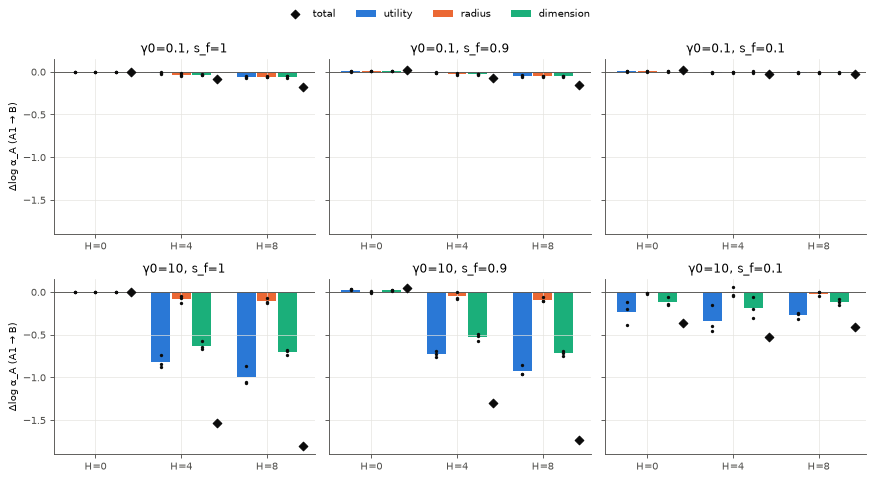

In [18]:
CH = [("utility", BLUE), ("radius", ORANGE), ("dimension", AQUA)]
if HAVE:
    fig, axes = plt.subplots(len(cfg.gammas), len(cfg.s_fs), figsize=(11, 6), sharey=True, squeeze=False)
    for i, g in enumerate(cfg.gammas):
        for j, sf in enumerate(cfg.s_fs):
            ax = axes[i, j]
            for k, h in enumerate(cfg.hammings):
                rs = sel(g, h, sf)
                if not rs: continue
                for ci, (ch, col) in enumerate(CH):
                    v = [r["backward"]["A1_to_B"][ch] for r in rs]; x = k + (ci - 1) * 0.24
                    ax.bar(x, np.mean(v), width=0.22, color=col, label=ch if (i, j, k) == (0, 0, 0) else None)
                    ax.scatter([x] * len(v), v, s=9, color=INK, zorder=3, linewidths=0)
                tot = [r["backward"]["A1_to_B"]["total"] for r in rs]
                ax.scatter([k + 0.42], [np.mean(tot)], marker="D", s=30, color=INK, zorder=4,
                           label="total" if (i, j, k) == (0, 0, 0) else None)
            ax.axhline(0, color=MUTED, linewidth=0.8)
            ax.set_xticks(range(len(cfg.hammings)), [f"H={h}" for h in cfg.hammings])
            ax.set_title(f"γ0={g:g}, s_f={sf:g}")
        axes[i, 0].set_ylabel("Δlog α_A (A1 → B)")
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=4, frameon=False)
    plt.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

**Q2. Behavioural forgetting and relearning.** Test loss on A through A → B → A, seed 0, s_f = 0.9. Each phase is scaled to unit width, because the step counts differ by orders of magnitude across γ₀.

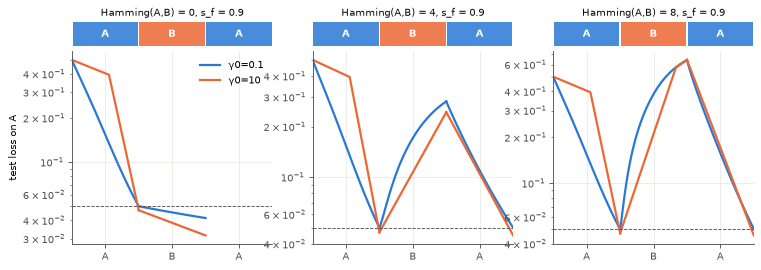

| γ0 | s_f | H | n | forgetting on B, test loss (vs running min) | forgetting on B, test acc (vs running max) | H/P | max |acc forgetting − H/P| over seeds | savings log((1+steps A1)/(1+steps A2)), mean [CI] | savings per seed | raw steps A1 (per seed) | raw steps B | raw steps A2 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | 3 | +0.0000 | +0.0000 | 0.0000 | 0.00e+00 | excluded¹ | — | 1610/1660/1935 | 0/0/0 | 0/0/0 |
| 0.1 | 1 | 4 | 3 | +0.2798 | +0.2500 | 0.2500 | 0.00e+00 | +0.568 [+0.183, +0.953] | +0.41 +0.72 +0.57 | 1610/1660/1935 | 1543/1240/1653 | 1067/807/1091 |
| 0.1 | 1 | 8 | 3 | +0.6988 | +0.4971 | 0.5000 | 8.75e-03 | +0.192 [+0.060, +0.324] | +0.13 +0.21 +0.24 | 1610/1660/1935 | 1997/1710/1754 | 1408/1352/1525 |
| 0.1 | 0.9 | 0 | 3 | -0.0002 | +0.0000 | 0.0000 | 0.00e+00 | +7.456 [+7.211, +7.701] | +7.38 +7.42 +7.57 | 1610/1660/1935 | 176/227/348 | 0/0/0 |
| 0.1 | 0.9 | 4 | 3 | +0.2318 | +0.2433 | 0.2500 | 1.75e-02 | +0.679 [+0.190, +1.167] | +0.45 +0.78 +0.80 | 1610/1660/1935 | 1525/1379/1565 | 1024/761/865 |
| 0.1 | 0.9 | 8 | 3 | +0.5432 | +0.4758 | 0.5000 | 3.63e-02 | +0.379 [+0.218, +0.541] | +0.30 +0.41 +0.42 | 1610/1660/1935 | 1918/1606/1547 | 1187/1102/1266 |
| 0.1 | 0.1 | 0 | 3 | +0.0211 | +0.0079 | 0.0000 | 1.62e-02 | +2.204 [+1.115, +3.292] | +1.86 +2.70 +2.05 | 1610/1660/1935 | 1601/1273/1486 | 250/111/247 |
| 0.1 | 0.1 | 4 | 3 | +0.0476 | +0.0283 | 0.2500 | 2.29e-01 | +1.405 [+0.945, +1.865] | +1.60 +1.39 +1.23 | 1610/1660/1935 | 1669/1454/1819 | 325/413/566 |
| 0.1 | 0.1 | 8 | 3 | +0.0365 | +0.0062 | 0.5000 | 5.00e-01 | +1.588 [+1.298, +1.879] | +1.47 +1.59 +1.70 | 1610/1660/1935 | 1430/1696/1422 | 369/338/351 |
| 10 | 1 | 0 | 3 | +0.0000 | +0.0000 | 0.0000 | 0.00e+00 | excluded¹ | — | 45/45/52 | 0/0/0 | 0/0/0 |
| 10 | 1 | 4 | 3 | +0.2616 | +0.2500 | 0.2500 | 0.00e+00 | +1.090 [+0.647, +1.534] | +0.88 +1.19 +1.20 | 45/45/52 | 25/19/20 | 18/13/15 |
| 10 | 1 | 8 | 3 | +0.7077 | +0.5000 | 0.5000 | 0.00e+00 | +0.435 [+0.063, +0.806] | +0.27 +0.46 +0.57 | 45/45/52 | 38/38/29 | 34/28/29 |
| 10 | 0.9 | 0 | 3 | -0.0137 | +0.0000 | 0.0000 | 0.00e+00 | +3.876 [+3.673, +4.079] | +3.83 +3.83 +3.97 | 45/45/52 | 3/2/4 | 0/0/0 |
| 10 | 0.9 | 4 | 3 | +0.2185 | +0.2433 | 0.2500 | 1.62e-02 | +1.454 [+1.040, +1.868] | +1.26 +1.53 +1.57 | 45/45/52 | 23/20/21 | 12/9/10 |
| 10 | 0.9 | 8 | 3 | +0.5611 | +0.4875 | 0.5000 | 1.88e-02 | +1.105 [+0.757, +1.452] | +1.00 +1.06 +1.26 | 45/45/52 | 30/28/23 | 16/15/14 |
| 10 | 0.1 | 0 | 3 | +0.0072 | +0.0100 | 0.0000 | 1.62e-02 | +3.414 [+2.504, +4.324] | +3.14 +3.83 +3.28 | 45/45/52 | 22/16/20 | 1/0/1 |
| 10 | 0.1 | 4 | 3 | +0.0228 | +0.0133 | 0.2500 | 2.50e-01 | +2.742 [+1.780, +3.705] | +3.14 +2.73 +2.36 | 45/45/52 | 20/21/25 | 1/2/4 |
| 10 | 0.1 | 8 | 3 | +0.0183 | +0.0021 | 0.5000 | 4.99e-01 | +2.952 [+1.057, +4.847] | +2.44 +3.83 +2.58 | 45/45/52 | 22/24/21 | 3/0/3 |

¹ Identity cell (H0, s_f 1.0): B and A2 take 0 steps, so the savings log ratio is log(1+steps A1) by construction. It is excluded from every savings summary.

accuracy forgetting vs H/P: max deviation over all cells and seeds = 5.00e-01


In [19]:
ACC_DEV = []
if HAVE:
    SF = 0.9 if 0.9 in cfg.s_fs else cfg.s_fs[0]
    fig = plt.figure(figsize=(11, 3.6))
    gs = fig.add_gridspec(2, len(cfg.hammings), height_ratios=[0.12, 1], hspace=0.05)
    for k, h in enumerate(cfg.hammings):
        stream_strip(fig.add_subplot(gs[0, k]), h, SF)
        ax = fig.add_subplot(gs[1, k])
        for g in cfg.gammas:
            rs = sel(g, h, SF)
            r = next((x for x in rs if x["spec"]["seed"] == 0), None)
            if r is None: continue
            for p, ph in enumerate(("A1", "B", "A2")):
                rec = r["trajectory"][ph]; st = np.array([q["step"] for q in rec], float)
                x = p + (st / st.max() if st.max() > 0 else np.zeros_like(st))
                ax.plot(x, [q["A_test_loss"] for q in rec], color=GAMMA_COL[g], label=f"γ0={g:g}" if p == 0 else None)
        ax.axhline(cfg.target_loss, color=MUTED, linewidth=0.8, linestyle="--")
        ax.set_yscale("log"); ax.set_xlim(0, 3); ax.set_xticks([0.5, 1.5, 2.5], ["A", "B", "A"])
        if k == 0: ax.set_ylabel("test loss on A"); ax.legend(frameon=False)
    plt.show()
    rows = []
    for g in cfg.gammas:
        for sf in cfg.s_fs:
            for h in cfg.hammings:
                rs = sel(g, h, sf)
                if not rs: continue
                fl = [r["behaviour"]["forget_B_loss"]["forgetting"] for r in rs]
                fa = [r["behaviour"]["forget_B_acc"]["forgetting"] for r in rs]
                dev = max(abs(x - h / cfg.P) for x in fa); ACC_DEV.append((g, sf, h, dev))
                sv = [r["behaviour"]["savings"] for r in rs]
                stp = lambda p: "/".join(str(r["behaviour"]["steps"][p]) for r in rs)
                ident = IDENTITY(h, sf)
                rows.append([f"{g:g}", f"{sf:g}", h, len(rs), f"{np.mean(fl):+.4f}", f"{np.mean(fa):+.4f}", f"{h / cfg.P:.4f}", f"{dev:.2e}",
                             "excluded¹" if ident else mci(sv), "—" if ident else " ".join(f"{x:+.2f}" for x in sv),
                             stp("A1"), stp("B"), stp("A2")])
    md_table(["γ0", "s_f", "H", "n", "forgetting on B, test loss (vs running min)", "forgetting on B, test acc (vs running max)",
              "H/P", "max |acc forgetting − H/P| over seeds",
              "savings log((1+steps A1)/(1+steps A2)), mean [CI]", "savings per seed", "raw steps A1 (per seed)", "raw steps B", "raw steps A2"], rows)
    display(Markdown("¹ Identity cell (H0, s_f 1.0): B and A2 take 0 steps, so the savings log ratio is "
                     "log(1+steps A1) by construction. It is excluded from every savings summary."))
    print(f"accuracy forgetting vs H/P: max deviation over all cells and seeds = {max(d for *_, d in ACC_DEV):.2e}")

**Q2b. Refit probe: the behavioural counterpart of capacity.** A fresh linear readout (u = 0)
is fitted on the frozen hidden features of A's training points by full-batch GD with the
network's own s and lr, for a fixed budget of `cfg.refit_steps` steps (no early stop). It is
then scored on A's test points. In μP, lr·s² = lr0/N, so the effective readout step is the same
at both γ₀ given the features. The init column is the random-feature baseline, identical across
γ₀. The trained-readout columns show the network's own readout at the same boundaries.

In [20]:
RB = ("init", "A1", "B", "A2")
if HAVE:
    print(f"refit budget: {cfg.refit_steps} steps; checkpoints also stored at {L.REFIT_CHECKPOINTS}")
    rows = []
    for g, sf, h in CELLS:
        rs = sel(g, h, sf)
        if not rs: continue
        tl = lambda ph: np.mean([r["trajectory"][ph][-1]["A_test_loss"] for r in rs])
        ta = lambda ph: np.mean([r["trajectory"][ph][-1]["A_test_acc"] for r in rs])
        dl = [math.log(r["refit"]["B"]["loss"] / r["refit"]["A1"]["loss"]) for r in rs]
        rows.append([f"{g:g}", f"{sf:g}", h]
                    + [f"{np.mean([r['refit'][b]['loss'] for r in rs]):.4f}" for b in RB]
                    + [f"{np.mean([r['refit'][b]['acc'] for r in rs]):.3f}" for b in RB]
                    + [mci(dl), f"{tl('A1'):.4f} / {tl('B'):.4f} / {tl('A2'):.4f}", f"{ta('A1'):.3f} / {ta('B'):.3f} / {ta('A2'):.3f}"])
    md_table(["γ0", "s_f", "H", "refit test loss: init", "after A", "after B", "after A again",
              "refit test acc: init", "after A", "after B", "after A again",
              "log(refit loss after B / after A), mean [CI]", "trained readout test loss A / B / A", "trained readout test acc A / B / A"], rows)

refit budget: 2000 steps; checkpoints also stored at (100, 500)


| γ0 | s_f | H | refit test loss: init | after A | after B | after A again | refit test acc: init | after A | after B | after A again | log(refit loss after B / after A), mean [CI] | trained readout test loss A / B / A | trained readout test acc A / B / A |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | 0.0801 | 0.0407 | 0.0407 | 0.0407 | 0.998 | 1.000 | 1.000 | 1.000 | +0.000 [+0.000, +0.000] | 0.0500 / 0.0500 / 0.0500 | 1.000 / 1.000 / 1.000 |
| 0.1 | 1 | 4 | 0.0801 | 0.0407 | 0.0520 | 0.0323 | 0.998 | 1.000 | 0.999 | 1.000 | +0.238 [-0.072, +0.549] | 0.0500 / 0.3298 / 0.0500 | 1.000 / 0.750 / 0.999 |
| 0.1 | 1 | 8 | 0.0801 | 0.0407 | 0.0659 | 0.0353 | 0.998 | 1.000 | 0.999 | 1.000 | +0.481 [+0.402, +0.560] | 0.0500 / 0.7488 / 0.0500 | 1.000 / 0.503 / 1.000 |
| 0.1 | 0.9 | 0 | 0.0801 | 0.0407 | 0.0377 | 0.0377 | 0.998 | 1.000 | 1.000 | 1.000 | -0.075 [-0.128, -0.023] | 0.0500 / 0.0401 / 0.0401 | 1.000 / 1.000 / 1.000 |
| 0.1 | 0.9 | 4 | 0.0801 | 0.0407 | 0.0494 | 0.0327 | 0.998 | 1.000 | 0.999 | 1.000 | +0.189 [-0.066, +0.444] | 0.0500 / 0.2818 / 0.0500 | 1.000 / 0.757 / 0.999 |
| 0.1 | 0.9 | 8 | 0.0801 | 0.0407 | 0.0626 | 0.0355 | 0.998 | 1.000 | 0.999 | 1.000 | +0.432 [+0.368, +0.495] | 0.0500 / 0.5932 / 0.0500 | 1.000 / 0.524 / 1.000 |
| 0.1 | 0.1 | 0 | 0.0801 | 0.0407 | 0.0382 | 0.0359 | 0.998 | 1.000 | 1.000 | 1.000 | -0.064 [-0.164, +0.036] | 0.0500 / 0.0699 / 0.0499 | 1.000 / 0.992 / 0.999 |
| 0.1 | 0.1 | 4 | 0.0801 | 0.0407 | 0.0421 | 0.0363 | 0.998 | 1.000 | 0.999 | 1.000 | +0.025 [-0.206, +0.257] | 0.0500 / 0.0976 / 0.0500 | 1.000 / 0.972 / 0.997 |
| 0.1 | 0.1 | 8 | 0.0801 | 0.0407 | 0.0427 | 0.0375 | 0.998 | 1.000 | 1.000 | 1.000 | +0.047 [-0.007, +0.100] | 0.0500 / 0.0865 / 0.0500 | 1.000 / 0.994 / 1.000 |
| 10 | 1 | 0 | 0.0801 | 0.0111 | 0.0111 | 0.0111 | 0.998 | 1.000 | 1.000 | 1.000 | +0.000 [+0.000, +0.000] | 0.0458 / 0.0458 / 0.0458 | 1.000 / 1.000 / 1.000 |
| 10 | 1 | 4 | 0.0801 | 0.0111 | 0.0298 | 0.0081 | 0.998 | 1.000 | 0.999 | 1.000 | +0.948 [-0.119, +2.015] | 0.0458 / 0.3074 / 0.0467 | 1.000 / 0.750 / 0.999 |
| 10 | 1 | 8 | 0.0801 | 0.0111 | 0.0459 | 0.0085 | 0.998 | 1.000 | 1.000 | 1.000 | +1.410 [+0.905, +1.914] | 0.0458 / 0.7534 / 0.0483 | 1.000 / 0.500 / 1.000 |
| 10 | 0.9 | 0 | 0.0801 | 0.0111 | 0.0104 | 0.0104 | 0.998 | 1.000 | 1.000 | 1.000 | -0.066 [-0.122, -0.010] | 0.0458 / 0.0321 / 0.0321 | 1.000 / 1.000 / 1.000 |
| 10 | 0.9 | 4 | 0.0801 | 0.0111 | 0.0226 | 0.0092 | 0.998 | 1.000 | 1.000 | 1.000 | +0.710 [+0.249, +1.171] | 0.0458 / 0.2643 / 0.0454 | 1.000 / 0.757 / 0.999 |
| 10 | 0.9 | 8 | 0.0801 | 0.0111 | 0.0382 | 0.0100 | 0.998 | 1.000 | 1.000 | 1.000 | +1.232 [+0.993, +1.471] | 0.0458 / 0.6069 / 0.0465 | 1.000 / 0.513 / 1.000 |
| 10 | 0.1 | 0 | 0.0801 | 0.0111 | 0.0150 | 0.0143 | 0.998 | 1.000 | 1.000 | 1.000 | +0.301 [-0.111, +0.712] | 0.0458 / 0.0530 / 0.0475 | 1.000 / 0.990 / 0.993 |
| 10 | 0.1 | 4 | 0.0801 | 0.0111 | 0.0164 | 0.0141 | 0.998 | 1.000 | 1.000 | 1.000 | +0.383 [+0.079, +0.688] | 0.0458 / 0.0686 / 0.0461 | 1.000 / 0.987 / 0.998 |
| 10 | 0.1 | 8 | 0.0801 | 0.0111 | 0.0142 | 0.0127 | 0.998 | 1.000 | 1.000 | 1.000 | +0.246 [+0.177, +0.316] | 0.0458 / 0.0640 / 0.0444 | 1.000 / 0.998 / 1.000 |

**Q3. Forward transfer.** Does the geometric change A made on B's manifolds go with behavioural forward transfer? **Specific FT_geo** = Δlog α_{y_B} − mean_k Δlog α_{y\*_k}, init → after A, against K = 4 neutral probes (balanced, s_r(y\*_k, y_A) = 0, fixed per seed). **Specific FT_beh** = FT_beh(cell) − FT_beh(H8, s_f 0.1), paired per seed within γ₀ (warm-start baseline), with FT_beh = log((1+steps fresh)/(1+steps B)). The anchored y\* (s_r = +0.5 to y_A) is kept as one labelled column. Hamming 0 with s_f 1.0 is excluded. Panels are stratified by s_f; nothing is pooled.

| seed | s_r(y* anchored, y_A) | s_r(y*_k neutral, y_A), k = 0..3 |
|---|---|---|
| 0 | +0.500 | +0.000 +0.000 +0.000 +0.000 |
| 1 | +0.500 | +0.000 +0.000 +0.000 +0.000 |
| 2 | +0.500 | +0.000 +0.000 +0.000 +0.000 |

neutral probes: s_r(y*_k, y_A) = 0 for every k and seed: True


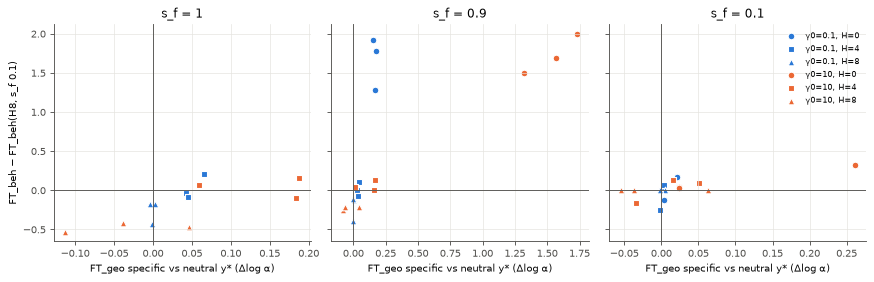

| γ0 | s_f | H | Δlog α_{y_B} total | utility | radius | dimension | mean Δlog α_{y*_k} (neutral) | FT_geo specific (neutral), mean [CI] | FT_geo specific, anchored y* (comparison) | FT_beh, mean [CI] | FT_beh specific (− H8, s_f 0.1), mean [CI] | zero-shot loss on B | raw steps B (per seed) | raw steps fresh B |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 4 | +0.059 | +0.006 | +0.023 | +0.030 | +0.008 | +0.051 [+0.019, +0.082] | -0.002 | +0.254 [+0.000, +0.508] | +0.027 [-0.370, +0.424] | 0.448 | 1543/1240/1653 | 1800/1775/2123 |
| 0.1 | 1 | 8 | +0.007 | -0.004 | +0.005 | +0.006 | +0.008 | -0.001 [-0.007, +0.006] | -0.054 | -0.035 [-0.171, +0.102] | -0.262 [-0.630, +0.105] | 0.834 | 1997/1710/1754 | 2031/1661/1599 |
| 0.1 | 0.9 | 0 | +0.173 | +0.053 | +0.055 | +0.065 | +0.007 | +0.166 [+0.137, +0.194] | +0.127 | +1.890 [+1.278, +2.502] | +1.663 [+0.834, +2.491] | 0.068 | 176/227/348 | 1470/1561/1777 |
| 0.1 | 0.9 | 4 | +0.044 | +0.007 | +0.018 | +0.020 | +0.007 | +0.037 [+0.016, +0.058] | -0.002 | +0.240 [+0.136, +0.345] | +0.013 [-0.218, +0.245] | 0.464 | 1525/1379/1565 | 1848/1792/2045 |
| 0.1 | 0.9 | 8 | +0.007 | -0.005 | +0.007 | +0.005 | +0.007 | +0.000 [-0.007, +0.007] | -0.038 | +0.021 [-0.130, +0.171] | -0.207 [-0.596, +0.183] | 0.787 | 1918/1606/1547 | 2058/1669/1476 |
| 0.1 | 0.1 | 0 | +0.009 | +0.005 | +0.003 | +0.002 | -0.000 | +0.009 [-0.016, +0.034] | +0.008 | +0.261 [+0.127, +0.395] | +0.034 [-0.339, +0.407] | 0.421 | 1601/1273/1486 | 2057/1753/1840 |
| 0.1 | 0.1 | 4 | +0.000 | +0.000 | +0.000 | -0.001 | -0.000 | +0.000 [-0.007, +0.007] | -0.001 | +0.169 [-0.003, +0.340] | -0.059 [-0.479, +0.362] | 0.517 | 1669/1454/1819 | 2024/1816/1992 |
| 0.1 | 0.1 | 8 | +0.001 | -0.001 | -0.000 | +0.001 | -0.000 | +0.001 [-0.007, +0.009] | -0.000 | +0.227 [-0.022, +0.476] | baseline (0) | 0.505 | 1430/1696/1422 | 1732/1970/1999 |
| 10 | 1 | 4 | +0.464 | +0.023 | +0.114 | +0.327 | +0.321 | +0.144 [-0.039, +0.326] | -0.019 | +0.805 [+0.434, +1.176] | +0.042 [-0.290, +0.375] | 0.432 | 25/19/20 | 48/47/51 |
| 10 | 1 | 8 | +0.286 | -0.072 | +0.110 | +0.248 | +0.321 | -0.035 [-0.233, +0.163] | -0.197 | +0.294 [-0.010, +0.598] | -0.469 [-0.609, -0.329] | 0.809 | 38/38/29 | 50/46/45 |
| 10 | 0.9 | 0 | +1.804 | +0.786 | +0.122 | +0.896 | +0.265 | +1.539 [+1.022, +2.056] | +1.416 | +2.490 [+2.011, +2.969] | +1.727 [+1.106, +2.347] | 0.068 | 3/2/4 | 44/44/51 |
| 10 | 0.9 | 4 | +0.377 | -0.000 | +0.102 | +0.276 | +0.265 | +0.112 [-0.109, +0.334] | -0.011 | +0.820 [+0.631, +1.010] | +0.057 [-0.117, +0.231] | 0.435 | 23/20/21 | 49/48/52 |
| 10 | 0.9 | 8 | +0.231 | -0.076 | +0.081 | +0.226 | +0.265 | -0.033 [-0.200, +0.133] | -0.157 | +0.536 [+0.324, +0.747] | -0.227 [-0.280, -0.175] | 0.758 | 30/28/23 | 51/45/44 |
| 10 | 0.1 | 0 | +0.085 | -0.021 | +0.039 | +0.067 | -0.018 | +0.103 [-0.238, +0.443] | +0.109 | +0.894 [+0.564, +1.224] | +0.131 [-0.287, +0.549] | 0.419 | 22/16/20 | 49/47/49 |
| 10 | 0.1 | 4 | -0.007 | -0.035 | -0.003 | +0.031 | -0.018 | +0.011 [-0.095, +0.116] | +0.018 | +0.781 [+0.536, +1.025] | +0.018 [-0.383, +0.418] | 0.498 | 20/21/25 | 49/48/50 |
| 10 | 0.1 | 8 | -0.028 | -0.046 | -0.012 | +0.031 | -0.018 | -0.010 [-0.167, +0.147] | -0.003 | +0.763 [+0.594, +0.933] | baseline (0) | 0.504 | 22/24/21 | 47/50/50 |

In [21]:
MARK = dict(zip(cfg.hammings, ["o", "s", "^", "v", "P"]))
BASE_CELL = (8, 0.1)
def ft_beh_spec(r):
    b = [x for x in sel(r["spec"]["gamma"], *BASE_CELL) if x["spec"]["seed"] == r["spec"]["seed"]]
    return r["behaviour"]["FT_beh"] - b[0]["behaviour"]["FT_beh"]
if HAVE:
    srs = sorted({r["spec"]["seed"]: r["relations"] for r in arms}.items())
    md_table(["seed", "s_r(y* anchored, y_A)", "s_r(y*_k neutral, y_A), k = 0..3"],
             [[s, f"{rel['s_r_ystar_A']:+.3f}", " ".join(f"{v:+.3f}" for v in rel["s_r_ystar_neutral_A"].values())] for s, rel in srs])
    print("neutral probes: s_r(y*_k, y_A) = 0 for every k and seed:",
          all(v == 0.0 for r in arms for v in r["relations"]["s_r_ystar_neutral_A"].values()))
if HAVE:
    fig, axes = plt.subplots(1, len(cfg.s_fs), figsize=(11, 3.6), sharey=True)
    for ax, sf in zip(axes, cfg.s_fs):
        for g in cfg.gammas:
            for h in cfg.hammings:
                if h == 0 and sf == 1.0: continue
                rs = sel(g, h, sf)
                ax.scatter([r["forward"]["specific"] for r in rs], [ft_beh_spec(r) for r in rs],
                           color=GAMMA_COL[g], marker=MARK[h], s=36, edgecolors="white", linewidths=1,
                           label=f"γ0={g:g}, H={h}" if sf == cfg.s_fs[-1] else None)
        ax.axhline(0, color=MUTED, linewidth=0.8); ax.axvline(0, color=MUTED, linewidth=0.8)
        ax.set_title(f"s_f = {sf:g}"); ax.set_xlabel("FT_geo specific vs neutral y* (Δlog α)")
    axes[0].set_ylabel("FT_beh − FT_beh(H8, s_f 0.1)"); axes[-1].legend(frameon=False, fontsize=7, loc="best"); plt.tight_layout(); plt.show()
    rows = []
    for g in cfg.gammas:
        for sf in cfg.s_fs:
            for h in cfg.hammings:
                rs = sel(g, h, sf)
                if not rs or (h == 0 and sf == 1.0): continue
                f = lambda k: np.mean([r["forward"]["total"][k] for r in rs])
                rows.append([f"{g:g}", f"{sf:g}", h, f"{f('total'):+.3f}", f"{f('utility'):+.3f}", f"{f('radius'):+.3f}",
                             f"{f('dimension'):+.3f}", f"{np.mean([r['forward']['ystar_neutral']['mean'] for r in rs]):+.3f}",
                             mci([r['forward']['specific'] for r in rs]),
                             f"{np.mean([r['forward']['specific_anchored'] for r in rs]):+.3f}",
                             mci([r['behaviour']['FT_beh'] for r in rs]),
                             "baseline (0)" if (h, sf) == BASE_CELL else mci([ft_beh_spec(r) for r in rs]),
                             f"{np.mean([r['behaviour']['first_loss']['B'] for r in rs]):.3f}",
                             "/".join(str(r["behaviour"]["steps"]["B"]) for r in rs),
                             "/".join(str(r["behaviour"]["steps"]["freshB"]) for r in rs)])
    md_table(["γ0", "s_f", "H", "Δlog α_{y_B} total", "utility", "radius", "dimension", "mean Δlog α_{y*_k} (neutral)",
              "FT_geo specific (neutral), mean [CI]", "FT_geo specific, anchored y* (comparison)", "FT_beh, mean [CI]",
              "FT_beh specific (− H8, s_f 0.1), mean [CI]",
              "zero-shot loss on B", "raw steps B (per seed)", "raw steps fresh B"], rows)

**Q4. Richness by phase.** Means over cells and seeds for each γ₀. ΔK and ΔK_u are relative to init, on A's fixed probe set. r_t is the weight change within a phase.

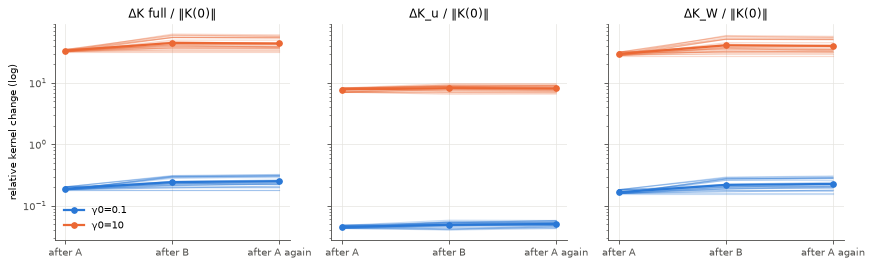

| γ0 | after | weight change from init | r_t (this phase) | ΔK full | ΔK_u | ΔK_W | ‖K_W‖/‖K‖ | CKA(K, y_A y_Aᵀ) | CKA(K_B, y_B y_Bᵀ) |
|---|---|---|---|---|---|---|---|---|---|
| 0.1 | A1 | 0.02 | 0.02 | 0.19 | 0.0453 | 0.167 | 0.149 | +0.267 | +0.218 |
| 0.1 | B | 0.0324 | 0.0259 | 0.244 | 0.0492 | 0.219 | 0.190 | +0.244 | +0.261 |
| 0.1 | A2 | 0.0306 | 0.0132 | 0.252 | 0.0508 | 0.228 | 0.195 | +0.265 | +0.242 |
| 10 | A1 | 0.615 | 0.615 | 33.5 | 7.81 | 29.7 | 0.870 | +0.355 | +0.236 |
| 10 | B | 0.739 | 0.402 | 44.9 | 8.25 | 41 | 0.897 | +0.275 | +0.317 |
| 10 | A2 | 0.734 | 0.19 | 44 | 8.15 | 40.2 | 0.896 | +0.321 | +0.276 |

**Phase-to-phase kernel change** (from the previous boundary: ‖·_now − ·_prev‖ / ‖K_prev‖_F; alignment = CKA(K_prev, K_now), 1 = same direction). Lines: mean over s_f and seeds per γ₀ × H, identity cell excluded (0 / 1 by construction). Table: per cell, mean [95% CI].

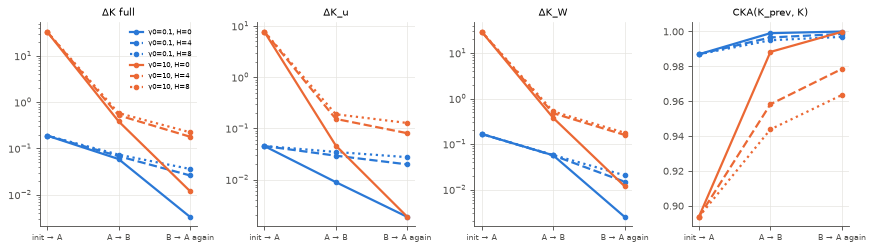

| γ0 | s_f | H | transition | ΔK full | ΔK_u | ΔK_W | CKA(K_prev, K) |
|---|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | A → B | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 0.1 | 1 | 0 | B → A again | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 0.1 | 1 | 4 | A → B | +0.0504 [+0.0471, +0.0538] | +0.0373 [+0.0338, +0.0407] | +0.0307 [+0.0238, +0.0375] | +0.9957 [+0.9953, +0.9960] |
| 0.1 | 1 | 4 | B → A again | +0.0321 [+0.0250, +0.0391] | +0.0273 [+0.0230, +0.0317] | +0.0158 [+0.0081, +0.0235] | +0.9977 [+0.9972, +0.9983] |
| 0.1 | 1 | 8 | A → B | +0.0580 [+0.0342, +0.0818] | +0.0458 [+0.0447, +0.0470] | +0.0302 [-0.0017, +0.0620] | +0.9932 [+0.9915, +0.9949] |
| 0.1 | 1 | 8 | B → A again | +0.0473 [+0.0458, +0.0488] | +0.0410 [+0.0398, +0.0423] | +0.0225 [+0.0186, +0.0265] | +0.9946 [+0.9941, +0.9952] |
| 0.1 | 0.9 | 0 | A → B | +0.0187 [+0.0060, +0.0313] | +0.0044 [+0.0021, +0.0066] | +0.0166 [+0.0046, +0.0287] | +0.9999 [+0.9998, +1.0000] |
| 0.1 | 0.9 | 0 | B → A again | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 0.1 | 0.9 | 4 | A → B | +0.0566 [+0.0529, +0.0603] | +0.0342 [+0.0309, +0.0375] | +0.0422 [+0.0378, +0.0466] | +0.9963 [+0.9957, +0.9969] |
| 0.1 | 0.9 | 4 | B → A again | +0.0299 [+0.0239, +0.0360] | +0.0241 [+0.0231, +0.0251] | +0.0160 [+0.0045, +0.0276] | +0.9983 [+0.9981, +0.9984] |
| 0.1 | 0.9 | 8 | A → B | +0.0606 [+0.0205, +0.1007] | +0.0414 [+0.0349, +0.0479] | +0.0405 [-0.0043, +0.0853] | +0.9943 [+0.9918, +0.9967] |
| 0.1 | 0.9 | 8 | B → A again | +0.0454 [+0.0389, +0.0519] | +0.0348 [+0.0292, +0.0404] | +0.0265 [+0.0074, +0.0456] | +0.9962 [+0.9953, +0.9972] |
| 0.1 | 0.1 | 0 | A → B | +0.0996 [+0.0732, +0.1260] | +0.0134 [+0.0088, +0.0181] | +0.0968 [+0.0706, +0.1230] | +0.9981 [+0.9975, +0.9988] |
| 0.1 | 0.1 | 0 | B → A again | +0.0066 [+0.0029, +0.0103] | +0.0037 [+0.0009, +0.0065] | +0.0050 [+0.0023, +0.0078] | +0.9999 [+0.9999, +1.0000] |
| 0.1 | 0.1 | 4 | A → B | +0.0976 [+0.0760, +0.1191] | +0.0163 [+0.0137, +0.0189] | +0.0965 [+0.0805, +0.1125] | +0.9977 [+0.9977, +0.9978] |
| 0.1 | 0.1 | 4 | B → A again | +0.0163 [+0.0081, +0.0245] | +0.0079 [+0.0039, +0.0118] | +0.0127 [+0.0065, +0.0190] | +0.9998 [+0.9997, +0.9999] |
| 0.1 | 0.1 | 8 | A → B | +0.1024 [+0.0978, +0.1069] | +0.0167 [+0.0118, +0.0216] | +0.1023 [+0.0980, +0.1066] | +0.9974 [+0.9967, +0.9982] |
| 0.1 | 0.1 | 8 | B → A again | +0.0154 [+0.0107, +0.0201] | +0.0063 [+0.0049, +0.0078] | +0.0127 [+0.0090, +0.0164] | +0.9999 [+0.9998, +0.9999] |
| 10 | 1 | 0 | A → B | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 10 | 1 | 0 | B → A again | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 10 | 1 | 4 | A → B | +0.3830 [+0.2671, +0.4988] | +0.1964 [+0.1378, +0.2549] | +0.3045 [+0.2167, +0.3923] | +0.9454 [+0.9156, +0.9751] |
| 10 | 1 | 4 | B → A again | +0.2675 [+0.2370, +0.2979] | +0.1305 [+0.1062, +0.1547] | +0.2295 [+0.1948, +0.2642] | +0.9609 [+0.9552, +0.9666] |
| 10 | 1 | 8 | A → B | +0.4471 [+0.2981, +0.5961] | +0.2553 [+0.1954, +0.3152] | +0.3378 [+0.1955, +0.4802] | +0.9205 [+0.8957, +0.9454] |
| 10 | 1 | 8 | B → A again | +0.3515 [+0.2931, +0.4098] | +0.2165 [+0.1724, +0.2605] | +0.2646 [+0.2364, +0.2929] | +0.9314 [+0.9044, +0.9584] |
| 10 | 0.9 | 0 | A → B | +0.1110 [+0.0563, +0.1657] | +0.0224 [+0.0145, +0.0303] | +0.1025 [+0.0472, +0.1577] | +0.9987 [+0.9966, +1.0009] |
| 10 | 0.9 | 0 | B → A again | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +0.0000 [+0.0000, +0.0000] | +1.0000 [+1.0000, +1.0000] |
| 10 | 0.9 | 4 | A → B | +0.4242 [+0.3232, +0.5253] | +0.1807 [+0.1157, +0.2457] | +0.3753 [+0.2992, +0.4513] | +0.9584 [+0.9394, +0.9773] |
| 10 | 0.9 | 4 | B → A again | +0.2099 [+0.1934, +0.2265] | +0.0982 [+0.0787, +0.1178] | +0.1868 [+0.1558, +0.2177] | +0.9765 [+0.9736, +0.9794] |
| 10 | 0.9 | 8 | A → B | +0.4787 [+0.2571, +0.7003] | +0.2295 [+0.1538, +0.3053] | +0.4072 [+0.2013, +0.6132] | +0.9425 [+0.9253, +0.9597] |
| 10 | 0.9 | 8 | B → A again | +0.2699 [+0.1897, +0.3502] | +0.1566 [+0.1060, +0.2073] | +0.2181 [+0.1743, +0.2619] | +0.9610 [+0.9380, +0.9840] |
| 10 | 0.1 | 0 | A → B | +0.6639 [+0.3743, +0.9535] | +0.0699 [+0.0325, +0.1074] | +0.6539 [+0.3507, +0.9572] | +0.9778 [+0.9568, +0.9988] |
| 10 | 0.1 | 0 | B → A again | +0.0239 [-0.0292, +0.0769] | +0.0037 [-0.0045, +0.0120] | +0.0236 [-0.0289, +0.0761] | +0.9996 [+0.9987, +1.0005] |
| 10 | 0.1 | 4 | A → B | +0.7540 [+0.6235, +0.8845] | +0.0822 [+0.0617, +0.1027] | +0.7524 [+0.5999, +0.9048] | +0.9709 [+0.9529, +0.9888] |
| 10 | 0.1 | 4 | B → A again | +0.0602 [-0.0020, +0.1223] | +0.0127 [+0.0041, +0.0212] | +0.0600 [-0.0060, +0.1260] | +0.9982 [+0.9948, +1.0017] |
| 10 | 0.1 | 8 | A → B | +0.8207 [+0.5826, +1.0587] | +0.0814 [+0.0497, +0.1131] | +0.8215 [+0.5830, +1.0600] | +0.9684 [+0.9544, +0.9824] |
| 10 | 0.1 | 8 | B → A again | +0.0487 [-0.0563, +0.1538] | +0.0092 [-0.0108, +0.0293] | +0.0492 [-0.0567, +0.1551] | +0.9983 [+0.9946, +1.0020] |

In [22]:
if HAVE:
    PH = ("A1", "B", "A2")
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
    for ax, (k, lab) in zip(axes, [("dK_full", "ΔK full"), ("dK_u", "ΔK_u"), ("dK_W", "ΔK_W")]):
        for g in cfg.gammas:
            rs = sel(g)
            per = np.array([[r["richness"][ph][k] for ph in PH] for r in rs])
            for row in per:
                ax.plot(range(3), row, color=GAMMA_COL[g], alpha=0.25, linewidth=1)
            ax.plot(range(3), per.mean(0), color=GAMMA_COL[g], marker="o", markersize=5, label=f"γ0={g:g}")
        ax.set_yscale("log"); ax.set_xticks(range(3), ["after A", "after B", "after A again"]); ax.set_title(f"{lab} / ‖K(0)‖")
    axes[0].set_ylabel("relative kernel change (log)"); axes[0].legend(frameon=False); plt.tight_layout(); plt.show()
    rows = []
    for g in cfg.gammas:
        rs = sel(g)
        for ph in PH:
            m = lambda k: np.mean([r["richness"][ph][k] for r in rs])
            rows.append([f"{g:g}", ph, f"{m('weight_change'):.3g}", f"{np.mean([r['richness']['r_t'][ph] for r in rs]):.3g}",
                         f"{m('dK_full'):.3g}", f"{m('dK_u'):.3g}", f"{m('dK_W'):.3g}", f"{m('KW_share'):.3f}",
                         f"{m('cka_K_yA'):+.3f}", f"{m('cka_K_yB'):+.3f}"])
    md_table(["γ0", "after", "weight change from init", "r_t (this phase)", "ΔK full", "ΔK_u", "ΔK_W", "‖K_W‖/‖K‖",
              "CKA(K, y_A y_Aᵀ)", "CKA(K_B, y_B y_Bᵀ)"], rows)
    display(Markdown("**Phase-to-phase kernel change** (from the previous boundary: ‖·_now − ·_prev‖ / ‖K_prev‖_F; "
                     "alignment = CKA(K_prev, K_now), 1 = same direction). Lines: mean over s_f and seeds per γ₀ × H, "
                     "identity cell excluded (0 / 1 by construction). Table: per cell, mean [95% CI]."))
    TR = (("A1", "init → A"), ("B", "A → B"), ("A2", "B → A again"))
    fig, axes = plt.subplots(1, 4, figsize=(11, 3.2))
    for ax, (k, lab) in zip(axes, [("dK_full_step", "ΔK full"), ("dK_u_step", "ΔK_u"), ("dK_W_step", "ΔK_W"), ("align_step", "CKA(K_prev, K)")]):
        for g in cfg.gammas:
            for hi, h in enumerate(cfg.hammings):
                rs = [r for r in sel(g, h) if not IDENTITY(h, r["spec"]["s_f"])]
                if rs: ax.plot(range(3), [np.mean([r["richness"][ph][k] for r in rs]) for ph, _ in TR], color=GAMMA_COL[g],
                               linestyle=["-", "--", ":", "-."][hi], marker="o", markersize=4,
                               label=f"γ0={g:g}, H={h}" if k == "dK_full_step" else None)
        if k != "align_step": ax.set_yscale("log")
        ax.set_xticks(range(3), [t for _, t in TR], fontsize=7); ax.set_title(lab, fontsize=9)
    axes[0].legend(frameon=False, fontsize=6); plt.tight_layout(); plt.show()
    rows = []
    for g, sf, h in CELLS:
        rs = sel(g, h, sf)
        if not rs: continue
        for ph, lab in TR[1:]:
            rows.append([f"{g:g}", f"{sf:g}", h, lab] + [mci([r["richness"][ph][k] for r in rs], 4) for k in
                                                         ("dK_full_step", "dK_u_step", "dK_W_step", "align_step")])
    md_table(["γ0", "s_f", "H", "transition", "ΔK full", "ΔK_u", "ΔK_W", "CKA(K_prev, K)"], rows)

**Q5. Centre correlation ρ_c on A's manifolds (signed, normalised), by boundary.** The `glue`-convention value is in a separate table only: it depends on the anchor norm and is not a direction measure.

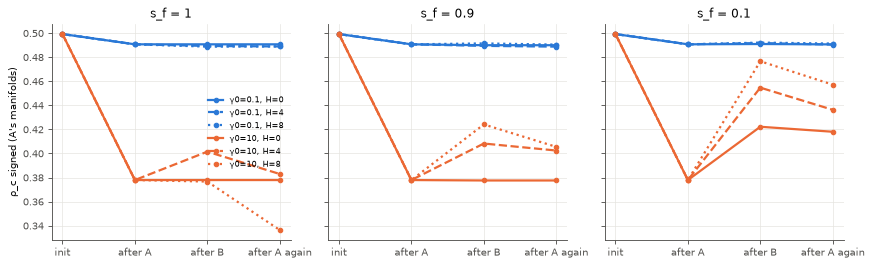

| γ0 | s_f | H | ρ_c signed: init | after A | after B | after A again |
|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | +0.499 [+0.495, +0.503] | +0.491 [+0.484, +0.497] | +0.491 [+0.484, +0.497] | +0.491 [+0.484, +0.497] |
| 0.1 | 1 | 4 | +0.499 [+0.495, +0.503] | +0.491 [+0.484, +0.497] | +0.489 [+0.483, +0.496] | +0.489 [+0.482, +0.496] |
| 0.1 | 1 | 8 | +0.499 [+0.495, +0.503] | +0.491 [+0.484, +0.497] | +0.489 [+0.481, +0.497] | +0.489 [+0.480, +0.498] |
| 0.1 | 0.9 | 0 | +0.499 [+0.495, +0.503] | +0.491 [+0.484, +0.497] | +0.490 [+0.483, +0.497] | +0.490 [+0.483, +0.497] |
| 0.1 | 0.9 | 4 | +0.499 [+0.495, +0.503] | +0.491 [+0.484, +0.497] | +0.489 [+0.484, +0.495] | +0.489 [+0.482, +0.496] |
| 0.1 | 0.9 | 8 | +0.499 [+0.495, +0.503] | +0.491 [+0.484, +0.497] | +0.491 [+0.484, +0.499] | +0.490 [+0.482, +0.499] |
| 0.1 | 0.1 | 0 | +0.499 [+0.495, +0.503] | +0.491 [+0.484, +0.497] | +0.491 [+0.483, +0.499] | +0.491 [+0.483, +0.498] |
| 0.1 | 0.1 | 4 | +0.499 [+0.495, +0.503] | +0.491 [+0.484, +0.497] | +0.492 [+0.485, +0.499] | +0.490 [+0.483, +0.498] |
| 0.1 | 0.1 | 8 | +0.499 [+0.495, +0.503] | +0.491 [+0.484, +0.497] | +0.492 [+0.483, +0.501] | +0.491 [+0.483, +0.500] |
| 10 | 1 | 0 | +0.499 [+0.495, +0.503] | +0.378 [+0.272, +0.484] | +0.378 [+0.272, +0.484] | +0.378 [+0.272, +0.484] |
| 10 | 1 | 4 | +0.499 [+0.495, +0.503] | +0.378 [+0.272, +0.484] | +0.401 [+0.389, +0.414] | +0.383 [+0.332, +0.434] |
| 10 | 1 | 8 | +0.499 [+0.495, +0.503] | +0.378 [+0.272, +0.484] | +0.377 [+0.362, +0.392] | +0.336 [+0.230, +0.443] |
| 10 | 0.9 | 0 | +0.499 [+0.495, +0.503] | +0.378 [+0.272, +0.484] | +0.378 [+0.266, +0.489] | +0.378 [+0.266, +0.489] |
| 10 | 0.9 | 4 | +0.499 [+0.495, +0.503] | +0.378 [+0.272, +0.484] | +0.408 [+0.387, +0.430] | +0.402 [+0.348, +0.457] |
| 10 | 0.9 | 8 | +0.499 [+0.495, +0.503] | +0.378 [+0.272, +0.484] | +0.424 [+0.406, +0.442] | +0.405 [+0.399, +0.412] |
| 10 | 0.1 | 0 | +0.499 [+0.495, +0.503] | +0.378 [+0.272, +0.484] | +0.422 [+0.334, +0.510] | +0.418 [+0.333, +0.503] |
| 10 | 0.1 | 4 | +0.499 [+0.495, +0.503] | +0.378 [+0.272, +0.484] | +0.455 [+0.400, +0.509] | +0.436 [+0.391, +0.482] |
| 10 | 0.1 | 8 | +0.499 [+0.495, +0.503] | +0.378 [+0.272, +0.484] | +0.477 [+0.442, +0.511] | +0.457 [+0.391, +0.523] |

**ρ_c (glue convention): anchor-norm dependent, not a direction measure.** Table only; not used in any figure or reading.

| γ0 | s_f | H | ρ_c glue: init | after A | after B | after A again |
|---|---|---|---|---|---|---|
| 0.1 | 1 | 0 | 0.599 | 0.547 | 0.547 | 0.547 |
| 0.1 | 1 | 4 | 0.599 | 0.547 | 0.568 | 0.535 |
| 0.1 | 1 | 8 | 0.599 | 0.547 | 0.605 | 0.535 |
| 0.1 | 0.9 | 0 | 0.599 | 0.547 | 0.543 | 0.543 |
| 0.1 | 0.9 | 4 | 0.599 | 0.547 | 0.564 | 0.533 |
| 0.1 | 0.9 | 8 | 0.599 | 0.547 | 0.599 | 0.543 |
| 0.1 | 0.1 | 0 | 0.599 | 0.547 | 0.542 | 0.537 |
| 0.1 | 0.1 | 4 | 0.599 | 0.547 | 0.556 | 0.544 |
| 0.1 | 0.1 | 8 | 0.599 | 0.547 | 0.557 | 0.552 |
| 10 | 1 | 0 | 0.599 | 0.203 | 0.203 | 0.203 |
| 10 | 1 | 4 | 0.599 | 0.203 | 2.51 | 0.22 |
| 10 | 1 | 8 | 0.599 | 0.203 | 3.78 | 0.211 |
| 10 | 0.9 | 0 | 0.599 | 0.203 | 0.207 | 0.207 |
| 10 | 0.9 | 4 | 0.599 | 0.203 | 1.79 | 0.275 |
| 10 | 0.9 | 8 | 0.599 | 0.203 | 3.2 | 0.266 |
| 10 | 0.1 | 0 | 0.599 | 0.203 | 0.382 | 0.358 |
| 10 | 0.1 | 4 | 0.599 | 0.203 | 0.555 | 0.373 |
| 10 | 0.1 | 8 | 0.599 | 0.203 | 0.483 | 0.39 |

In [23]:
BND = ("A@init", "A@A1", "A@B", "A@A2")
LSTYLE = dict(zip(cfg.hammings, ["-", "--", ":", "-."]))
if HAVE:
    fig, axes = plt.subplots(1, len(cfg.s_fs), figsize=(11, 3.4), sharey=True)
    for ax, sf in zip(axes, cfg.s_fs):
        for g in cfg.gammas:
            for h in cfg.hammings:
                rs = sel(g, h, sf)
                if not rs: continue
                ax.plot(range(4), [np.mean([r["geometry"][b]["rho_c_signed"] for r in rs]) for b in BND],
                        color=GAMMA_COL[g], linestyle=LSTYLE[h], marker="o", markersize=4,
                        label=f"γ0={g:g}, H={h}" if sf == cfg.s_fs[0] else None)
        ax.set_xticks(range(4), ["init", "after A", "after B", "after A again"]); ax.set_title(f"s_f = {sf:g}")
    axes[0].set_ylabel("ρ_c signed (A's manifolds)"); axes[0].legend(frameon=False, fontsize=7); plt.tight_layout(); plt.show()
    rows = []
    for g in cfg.gammas:
        for sf in cfg.s_fs:
            for h in cfg.hammings:
                rs = sel(g, h, sf)
                if not rs: continue
                rows.append([f"{g:g}", f"{sf:g}", h] + [mci([r["geometry"][b]["rho_c_signed"] for r in rs]) for b in BND])
    md_table(["γ0", "s_f", "H", "ρ_c signed: init", "after A", "after B", "after A again"], rows)
    display(Markdown("**ρ_c (glue convention): anchor-norm dependent, not a direction measure.** Table only; not used in any figure or reading."))
    rows = []
    for g, sf, h in CELLS:
        rs = sel(g, h, sf)
        if rs: rows.append([f"{g:g}", f"{sf:g}", h] + [f"{np.mean([r['geometry'][b]['rho_c_glue'] for r in rs]):.3g}" for b in BND])
    md_table(["γ0", "s_f", "H", "ρ_c glue: init", "after A", "after B", "after A again"], rows)

## 7. Expectation readings

Each expectation is quoted verbatim from the cell written before the run and read by
the rule fixed there.

In [24]:
EXP = {1: "forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1",
       2: "at γ0 = 10, the utility channel carries most of Δlog α_A",
       3: "Hamming 0 under drift (s_f 0.9) gives Δlog α_A > 0 (gain)",
       4: "Hamming 4 and 8 are similar (cliff, not dose)",
       5: "K_u change separates γ0 more cleanly than the full NTK change"}
G_LO, G_HI = cfg.gammas
d_AB = lambda r: r["backward"]["A1_to_B"]
def by_seed(g, h, sf, f=lambda r: d_AB(r)["total"]):
    return {r["spec"]["seed"]: f(r) for r in sel(g, h, sf)}
def fmt(rv): return f"{rv['mean']:+.4f} [{rv['lo']:+.4f}, {rv['hi']:+.4f}] n={rv['n']}"
READ = []
if HAVE:
    for sf in cfg.s_fs:                                   # 1
        a, b = by_seed(G_HI, 8, sf), by_seed(G_LO, 8, sf)
        d = [a[s] - b[s] for s in sorted(set(a) & set(b))]
        fl = max(FL.values()); rv = resolve(d, fl)
        v = "held" if rv["sign"] < 0 else "not held" if rv["sign"] > 0 else "unresolved at floor"
        READ.append([1, f"s_f={sf:g}", f"d = Δ(γ0={G_HI:g}) − Δ(γ0={G_LO:g}) at H8: {fmt(rv)}", f"{fl:.4f}", v])
    cells2 = [(h, sf) for h in cfg.hammings if h > 0 for sf in cfg.s_fs] + [(0, sf) for sf in cfg.s_fs if sf < 1.0]
    for h, sf in cells2:                                  # 2
        rs = sel(G_HI, h, sf); tot = [d_AB(r)["total"] for r in rs]; ut = [d_AB(r)["utility"] for r in rs]
        rv = resolve(tot, FL[G_HI]); frac = np.mean(ut) / np.mean(tot)
        v = ("held" if frac > 0.5 else "not held") if rv["resolved"] else "unresolved at floor"
        READ.append([2, f"γ0={G_HI:g}, H={h}, s_f={sf:g}", f"total {fmt(rv)}; utility fraction {frac:+.3f}", f"{FL[G_HI]:.4f}", v])
    for g in cfg.gammas:                                  # 3
        rv = resolve(list(by_seed(g, 0, 0.9).values()), FL[g])
        v = "held" if rv["sign"] > 0 else "not held" if rv["sign"] < 0 else "unresolved at floor"
        READ.append([3, f"γ0={g:g}", f"Δlog α_A at H0, s_f 0.9: {fmt(rv)}", f"{FL[g]:.4f}", v])
    for g in cfg.gammas:                                  # 4
        for sf in cfg.s_fs:
            a, b = by_seed(g, 8, sf), by_seed(g, 4, sf)
            d = [a[s] - b[s] for s in sorted(set(a) & set(b))]
            rv = resolve(d, FL[g])
            if rv["lo"] > -2 * FL[g] and rv["hi"] < 2 * FL[g]: v = "held"
            elif rv["resolved"]: v = "not held"
            else: v = "unresolved at floor"
            READ.append([4, f"γ0={g:g}, s_f={sf:g}", f"d = Δ(H8) − Δ(H4): {fmt(rv)}; equivalence band ±{2 * FL[g]:.4f}", f"{FL[g]:.4f}", v])
    uniq = {}                                             # 5: phase A is identical across cells, so use unique (seed, γ0)
    for r in arms:
        uniq[(r["spec"]["seed"], r["spec"]["gamma"])] = r["richness"]["A1"]
    def dprime(k):
        lo = np.log([v[k] for (s, g), v in uniq.items() if g == G_LO]); hi = np.log([v[k] for (s, g), v in uniq.items() if g == G_HI])
        sp = math.sqrt((lo.var(ddof=1) + hi.var(ddof=1)) / 2)
        return (hi.mean() - lo.mean()) / sp, float(np.exp(lo).mean()), float(np.exp(hi).mean())
    du, dfu = dprime("dK_u"), dprime("dK_full")
    v = "held" if du[0] > dfu[0] else "not held"
    READ.append([5, "after A, unique (seed, γ0)",
                 f"d′(ΔK_u) = {du[0]:.1f} vs d′(ΔK full) = {dfu[0]:.1f}; lazy ΔK_u = {du[1]:.4f}, lazy ΔK full = {dfu[1]:.4f}; "
                 f"rich ΔK_u = {du[2]:.3g}, rich ΔK full = {dfu[2]:.3g}", "—", v])
    md_table(["#", "expectation (verbatim)", "stratum", "statistic (mean [95% CI])", "floor", "reading"],
             [[i, EXP[i], st, stat, fl, f"**{v}**"] for i, st, stat, fl, v in READ])
    lazyW = float(np.mean([v["dK_W"] for (s, g), v in uniq.items() if g == G_LO]))
    display(Markdown(
        f"**Note on expectation 5 (added 2026-11-08 after the first QUICK run; the reading above stays as computed).** "
        f"The criterion (d′ of log change) was mis-specified: it rewards any measure that grows by a large, consistent "
        f"factor, and K_W grows from exactly 0, so the full NTK wins on d′. The richness axis is **ΔK_u**, because it is "
        f"≈ 0 when lazy (ΔK_u = {du[1]:.3f} at γ0 = {G_LO:g}), while the full-NTK change at γ0 = {G_LO:g} "
        f"({dfu[1]:.3f}) is mostly K_W growth (ΔK_W = {lazyW:.3f})."))

| # | expectation (verbatim) | stratum | statistic (mean [95% CI]) | floor | reading |
|---|---|---|---|---|---|
| 1 | forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1 | s_f=1 | d = Δ(γ0=10) − Δ(γ0=0.1) at H8: -1.6321 [-1.9189, -1.3454] n=3 | 0.0829 | **held** |
| 1 | forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1 | s_f=0.9 | d = Δ(γ0=10) − Δ(γ0=0.1) at H8: -1.5758 [-1.8640, -1.2876] n=3 | 0.0829 | **held** |
| 1 | forgetting of A at Hamming 8 is larger at γ0 = 10 than at 0.1 | s_f=0.1 | d = Δ(γ0=10) − Δ(γ0=0.1) at H8: -0.3833 [-0.5375, -0.2291] n=3 | 0.0829 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=4, s_f=1 | total -1.5322 [-1.8441, -1.2202] n=3; utility fraction +0.535 | 0.0829 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=4, s_f=0.9 | total -1.3029 [-1.3899, -1.2158] n=3; utility fraction +0.560 | 0.0829 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=4, s_f=0.1 | total -0.5320 [-1.1560, +0.0920] n=3; utility fraction +0.632 | 0.0829 | **unresolved at floor** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=8, s_f=1 | total -1.8059 [-2.0880, -1.5239] n=3; utility fraction +0.552 | 0.0829 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=8, s_f=0.9 | total -1.7314 [-2.0260, -1.4368] n=3; utility fraction +0.532 | 0.0829 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=8, s_f=0.1 | total -0.4139 [-0.6015, -0.2263] n=3; utility fraction +0.663 | 0.0829 | **held** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=0, s_f=0.9 | total +0.0448 [-0.0022, +0.0917] n=3; utility fraction +0.607 | 0.0829 | **unresolved at floor** |
| 2 | at γ0 = 10, the utility channel carries most of Δlog α_A | γ0=10, H=0, s_f=0.1 | total -0.3659 [-0.7720, +0.0401] n=3; utility fraction +0.636 | 0.0829 | **unresolved at floor** |
| 3 | Hamming 0 under drift (s_f 0.9) gives Δlog α_A > 0 (gain) | γ0=0.1 | Δlog α_A at H0, s_f 0.9: +0.0211 [+0.0074, +0.0349] n=3 | 0.0448 | **unresolved at floor** |
| 3 | Hamming 0 under drift (s_f 0.9) gives Δlog α_A > 0 (gain) | γ0=10 | Δlog α_A at H0, s_f 0.9: +0.0448 [-0.0022, +0.0917] n=3 | 0.0829 | **unresolved at floor** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=0.1, s_f=1 | d = Δ(H8) − Δ(H4): -0.0878 [-0.1079, -0.0678] n=3; equivalence band ±0.0896 | 0.0448 | **unresolved at floor** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=0.1, s_f=0.9 | d = Δ(H8) − Δ(H4): -0.0870 [-0.1179, -0.0561] n=3; equivalence band ±0.0896 | 0.0448 | **unresolved at floor** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=0.1, s_f=0.1 | d = Δ(H8) − Δ(H4): -0.0104 [-0.1073, +0.0866] n=3; equivalence band ±0.0896 | 0.0448 | **unresolved at floor** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=10, s_f=1 | d = Δ(H8) − Δ(H4): -0.2737 [-0.5141, -0.0334] n=3; equivalence band ±0.1657 | 0.0829 | **not held** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=10, s_f=0.9 | d = Δ(H8) − Δ(H4): -0.4285 [-0.6480, -0.2090] n=3; equivalence band ±0.1657 | 0.0829 | **not held** |
| 4 | Hamming 4 and 8 are similar (cliff, not dose) | γ0=10, s_f=0.1 | d = Δ(H8) − Δ(H4): +0.1181 [-0.6557, +0.8920] n=3; equivalence band ±0.1657 | 0.0829 | **unresolved at floor** |
| 5 | K_u change separates γ0 more cleanly than the full NTK change | after A, unique (seed, γ0) | d′(ΔK_u) = 72.6 vs d′(ΔK full) = 98.9; lazy ΔK_u = 0.0453, lazy ΔK full = 0.1901; rich ΔK_u = 7.81, rich ΔK full = 33.5 | — | **not held** |

**Note on expectation 5 (added 2026-11-08 after the first QUICK run; the reading above stays as computed).** The criterion (d′ of log change) was mis-specified: it rewards any measure that grows by a large, consistent factor, and K_W grows from exactly 0, so the full NTK wins on d′. The richness axis is **ΔK_u**, because it is ≈ 0 when lazy (ΔK_u = 0.045 at γ0 = 0.1), while the full-NTK change at γ0 = 0.1 (0.190) is mostly K_W growth (ΔK_W = 0.167).

### Observations (n = 3, not claims)

Written 2026-11-09 after reading the QUICK grid. Provenance: commit `ee2c1b6`, clean stamps, `aba_lib`
hash `9cc174b574654db2`. Floors (trained representation): 0.045 at γ₀ = 0.1 and 0.083 at γ₀ = 10;
the init floor is 0.037. Nothing here is a finding until a pre-commit names its reading. This
replaces the 2026-11-08 observations. Phase A and every Δlog α_A value are bit-identical to that
run.

1. **Accuracy forgetting equals H/P for frozen input only (≈ 0 under jump), so its
   γ₀-independence under frozen input holds by construction.** *(Amended 2026-11-09.)*
   - At s_f 1 it is 0.25 and 0.50 at both γ₀. The max deviation is 0 in every case except
     lazy H8 (0.009).
   - B's points are A's points, and one shared scalar readout fits y_B there. So A's test
     accuracy becomes the agreement 1 − H/P, set by the label relation.
   - Under drift (s_f 0.9) it is close to H/P (0.24 and 0.48–0.49).
   - Under jump (s_f 0.1) it is ≈ 0 (≤ 0.03), because B is fitted on other inputs.
   - Test-loss forgetting tracks the same relation (0.26–0.28 at H4, 0.70–0.71 at H8, s_f 1).
   - The behavioural counterpart of capacity is the refit probe (observation 3), not this
     number. This rewords observation 1 of 11-08.
2. **As a fraction of what A built, B removes most of it at both γ₀ under frozen or drifting
   input; the γ₀ gap shrinks.**
   - The init→A gain is +2.02 at γ₀ = 10 and +0.22 at γ₀ = 0.1 (9×). Both gains are
     resolved.
   - Fraction removed under frozen input: H4 0.76 vs 0.39, H8 0.89 vs 0.79 (γ₀ = 10 vs 0.1).
   - Under drift: H4 0.65 vs 0.31, H8 0.86 vs 0.71.
   - At H8, both γ₀ end B close to the init level of log α_A (−0.81 and −0.98, against −1.02
     at init).
   - Relearning A brings both back to about the A1 level.
   - Under jump, the fraction is 0.2–0.27 at γ₀ = 10. At γ₀ = 0.1 it is 0.09–0.14, with CIs
     that include 0.
   - The large raw Δlog α gap across γ₀ (−1.8 vs −0.17) is therefore mostly a gap in how much
     A built.
3. **Channel split against the gain differs by γ₀.**
   - At γ₀ = 10 (H8, frozen), utility is −0.49 of the gain, dimension −0.35 and radius
     −0.05.
   - At γ₀ = 0.1 the three channels take about equal shares (−0.27, −0.26, −0.26).
4. **The refit probe: accuracy saturates, loss does not.**
   - A fresh readout on frozen features reaches test accuracy 0.998 on the untrained features
     and ≥ 0.999 everywhere else. At P = 16, N = 300, accuracy carries no information.
   - Test loss after the 2000-step budget falls from 0.080 at init to 0.041 (γ₀ = 0.1) and to
     0.011 (γ₀ = 10) after A.
   - After B at H8 (frozen) it rises to 0.066 (log ratio +0.48 [+0.40, +0.56]) and to 0.046
     (+1.41 [+0.91, +1.91]). So the relative damage is larger at γ₀ = 10, as for capacity.
   - In absolute terms, though, the rich features after B are about as good as the lazy
     features after A.
   - After relearning A, refit loss is below its A1 level at both γ₀.
5. **With a neutral baseline, the H8 sign disagreement of 11-08 goes away.**
   - The anchored y\* had s_r(y\*, y_A) = +0.5 for every seed. The neutral probes have
     s_r = 0.
   - A raises capacity for unrelated dichotomies on B's manifolds at γ₀ = 10: the mean neutral
     Δlog α is +0.32 (frozen), +0.27 (drift) and −0.02 (jump). That generic gain is now
     subtracted.
   - Specific FT_geo at γ₀ = 10, H8 is −0.035 (frozen) and −0.033 (drift), with CIs that
     include 0. With the anchored probe it was −0.20 and −0.16.
   - The large positive cell is unchanged: H0 drift is +1.54 at γ₀ = 10 and +0.17 at 0.1.
6. **Specific FT_beh (against H8, s_f 0.1 within γ₀) is negative at γ₀ = 10, H8, under frozen
   or drifting input.**
   - The values are −0.47 [−0.61, −0.33] (frozen) and −0.23 [−0.28, −0.18] (drift). At γ₀ = 0.1
     they are −0.26 and −0.21, with CIs that include 0.
   - So, against the warm-start baseline, a rich learner that relearns conflicting labels on
     the same inputs is slower.
   - H4 is ≈ 0 in every stratum. H0 drift is +1.66 and +1.73.
7. **Phase-to-phase, B moves the kernel at both γ₀; only at γ₀ = 10 does it change direction.**
   - Relative to ‖K_A1‖, the A → B change at γ₀ = 10 is 0.38–0.48 under frozen or drift, with
     CKA(K_A1, K_B) of 0.92–0.96.
   - Under jump it is larger in norm (0.66–0.82, almost all K_W), but more aligned (0.97). A
     second round of A then barely moves it (0.02–0.06).
   - At γ₀ = 0.1, ΔK_u from A to B is 0.03–0.05, the same size as init → A (0.045), and CKA is
     ≥ 0.993.
   - The transition values are each relative to their own previous kernel, so the transitions
     are not on one scale.
8. **The signed ρ_c falls when A is learned richly and partly recovers after B.**
   - At γ₀ = 10 it goes 0.50 → 0.38 after A, then rises to 0.38–0.48 after B (most under jump).
   - At γ₀ = 0.1 it stays at 0.49.
   - The `glue` value (2.5–3.8 after B, frozen H4–8) is in the table only; it depends on the
     anchor norm.